# Givers, Takers and the Shape of a City

- We model a **city** as a network of citizens who are either **givers** (cooperative strategies) or **takers** (exploitative ones), playing the **Iterated Prisoner's Dilemma** with the people they actually meet.
- We build the city in **six steps (S1 to S6)**, adding one mechanism at a time: from a well-mixed crowd, to a fixed network, to ties that fade, to partners chosen by proximity, habit and status, to a city that replaces the relationships it loses, and finally to a city whose citizens walk away from anyone who cheats them.
- We sweep the **share of givers** from 0 to 1 in every step and ask what happens to **prosperity** (wealth per person), **inequality** (Gini coefficient) and **structure** (who ends up connected to whom).
- What we find: more givers always make a city richer, but the richest cities are not the most equal. Without refusal, inequality is **positional**: it comes from who gets met, and a city where nobody is ever exploited is nearly as unequal as a mixed one. Giving citizens the right to walk away barely changes **how much** inequality there is, but changes **whose** it is: it moves onto the takers. A city that never forgives shuts its takers out completely, protects its givers, and becomes poorer and far more unequal where takers are common.

## Background and Goal

**The phenomenon:** communities of similar size and resources end up in very different places: some generate a lot of wealth and spread it widely, others generate less and concentrate it. Cooperation is part of the story, but its payoff is strongly context-dependent: across 83 studies and 957 estimates, the average effect of social capital on growth is close to zero, with large positive and negative effects in different settings [1]. What seems to matter is *who* is connected to whom: cross-class friendships predict upward mobility, while tight-knit cohesion does not [2].

**Why an agent-based model:** prosperity, inequality and social segregation are outcomes nobody in a city chooses. They emerge from many local interactions, each of which is simple to state. That is the case for simulating individual agents and their interactions rather than writing an equation for the aggregate [3].

**What is uncertain:** whether cooperation also makes a society more equal is contested. Network-game models find inequality falling as cooperation rises [4], [5]; laboratory networks with clustering produce more inequality and rich-poor segregation [6]; and making wealth visible amplifies initial advantage [7].

**Research question:**

> In simulated cities that differ in their mix of cooperative and exploitative agents, what patterns emerge in prosperity, in how that prosperity is distributed, and in who ends up connected to whom?

**Hypotheses:**

| # | Hypothesis | What would refute it |
|---|---|---|
| **H1** | **Prosperity threshold:** wealth per person rises with the share of givers, non-linearly, with a share below which cooperation cannot get established. | Wealth is a straight line in the giver share. |
| **H2** | **Prosperity and equality decouple:** inequality does not simply fall as givers increase; it flattens or rises in the richest cities, because cooperation relies on clusters [8], [9] and popular citizens attract more of the surplus. | Inequality falls steadily with the giver share on every network. |
| **H3** | **Emergent segregation:** givers end up tied to givers and takers are pushed to the edges, with no rule telling anyone to avoid anyone. | Class assortativity stays flat and takers keep giver-level ties. |
| **H4** | **The poverty trap is equal:** taker-dominated cities are poor but not unequal, so median wealth separates good cities from bad better than inequality does. | Taker-dominated cities are markedly unequal. |

H2 runs against the existing model results, so either answer is informative.

## The Model

### Citizens and the game

Every agent keeps one fixed strategy for the whole run. Each meeting is one round of the Prisoner's Dilemma, with the payoffs `(T, R, P, S) = (5, 3, 1, 0)` used in [3, Ch. 12]:

| | Opponent cooperates | Opponent defects |
|---|---|---|
| **You cooperate** | 3 | 0 |
| **You defect** | 5 | 1 |

Because `2R = 6 > T + S = 5 > 2P = 2`, a cooperating pair **creates** more wealth than an exploitative pair, which creates more than a mutually defecting pair. Wealth is created by interaction, not moved between agents, so a city's total wealth reports how its citizens have treated each other.

| Strategy | Behaviour | Class |
|---|---|---|
| **AllC** | Always cooperates. | Giver |
| **TFT** | Cooperates first, then copies the partner's last move. | Giver |
| **GTFT** | TFT, but forgives a defection with probability 0.1. | Giver |
| **TF2T** | Defects only after two defections in a row. | Giver |
| **Grudger** | Cooperates until the first defection, then defects forever. | Giver |
| **Pavlov** | Repeats its last move if it scored well, switches if not. | Giver |
| **AllD** | Always defects. | Taker |
| **Random** | Cooperates with probability 0.5. | Taker |
| **Joss** | TFT, but defects unprovoked with probability 0.1. Used only in *A Taker That Looks Like a Giver*. | Taker |

The **giver fraction** `f` is the share of agents drawn from the giver class; the mix within each class is fixed, so one number describes a city's population.

### Terms

- **Tie:** an acquaintance relationship, with a **strength** that grows with use and fades without it. A tie is not a meeting: having a tie means these two know each other.
- **Meeting:** one interaction in one round, which is one game of the Prisoner's Dilemma. Each agent starts one meeting per round and may be chosen by others.
- **Tie capacity:** the number of ties an agent may hold, fixed at its degree in the starting network, so a city keeps its degree distribution as ties break and form.
- **Popularity rating:** a bounded, slow-moving score of how cooperative and well-connected an agent has been. It is a coarse public signal, not perfect information.
- **Giver-dominated / taker-dominated:** cities with `f >= 0.7` and `f <= 0.3`.

### One round

```
for each round t in 1..T:
    1. every agent picks a partner        (proximity x habit x popularity; in S6, never
                                           someone it has walked away from)
    2. each pair plays one game           (each strategy sees its history with that partner)
    3. payoffs are added to wealth
    4. ties used this round get stronger
    5. unused ties decay with time since contact
    6. ties below the severance threshold break
    7. agents with spare capacity form new ties (friends of friends)
    8. popularity ratings update
```

Updating is synchronous: every choice in a round uses the state at the start of that round.

### The three rules that decide behaviour

Everything the model does comes from three rules, and S6 adds a fourth. Each one is given in symbols, then in plain
words, with the numbers we actually use.

**Rule 1: who meets whom**

Each week every citizen picks one person to meet, and not at random. Every possible partner `j`
gets a score, and the chance of picking them is their score divided by the total of all the
scores:

$$ s_{ij} = \underbrace{(w_{ij} + \varepsilon)^{\beta}}_{\text{habit}} \times \underbrace{R_j^{\gamma}}_{\text{standing}} \times \underbrace{d_{ij}^{-\lambda}}_{\text{closeness}} $$

- **Habit**, $w_{ij}$: how strong the relationship between `i` and `j` already is. Someone you
  see often scores higher. The small amount $\varepsilon = 0.1$ is added to everybody's score so
  that a person you have never met still has some chance of being picked. Without it no new
  relationship could ever start.
- **Standing**, $R_j$: how popular `j` is, a number between 0.1 and 1 defined in rule 3.
- **Closeness**, $d_{ij}$: how many handshakes away `j` is. A neighbour is 1 away and scores
  $1^{-1} = 1$. A friend of a friend is 2 away and scores $2^{-1} = 0.5$, so is half as likely,
  everything else being equal. We never look further than 3 handshakes. This $1/d$ shape is how
  the chance of a real social tie falls off with distance [10].
- The exponents $\beta$, $\gamma$ and $\lambda$ say how much each of the three counts. All are 1
  here, so the three count equally, and setting one to 0 switches that influence off. That is how
  the six steps below are built.
- **A worked example:** a well-liked neighbour you already see often ($w = 5$, $R = 0.9$,
  $d = 1$) scores $5.1 \times 0.9 \times 1 = 4.6$. A poorly rated stranger two handshakes away
  ($w = 0$, $R = 0.2$, $d = 2$) scores $0.1 \times 0.2 \times 0.5 = 0.01$. The neighbour is about
  450 times likelier to be chosen.
- Other people are choosing too, so a citizen can be picked by several in one week. The number of
  meetings anyone can **receive** is capped at $c_{max} = 4$ a week: attention is finite, and
  without a cap the most popular person soaks up an unlimited share of the city's meetings.

**Rule 2: relationships strengthen, fade and break**

- Every meeting adds $\delta = 1$ to the strength of that relationship.
- Strength fades with the time since the last meeting, $w \times e^{-\alpha \Delta t}$, at
  $\alpha = 0.05$ per week. This is **neglect, not punishment**: a relationship fades because it
  goes unused, whatever happened the last time the two met [11].
- When strength falls below $\theta = 0.1$ the relationship is dropped. Starting from a single
  meeting, that takes $\ln(10) / 0.05 \approx 46$ weeks without contact.
- A relationship is judged on **its own** strength, not against a better offer. Judging by
  comparison would freeze the city: someone you have never met has strength near 0, so they could
  never beat someone you already know.

**Rule 3: popularity, meaning how visible and well regarded someone is**

Each citizen carries a single number, their rating, standing for how good they are to meet. It is
built from two things any real citizen could notice:

- **How cooperative they have been lately**, $\kappa_j$: the share of their recent moves that
  were cooperative. It is a slow-moving average, so one bad week does not destroy a reputation
  and one good week does not make one.
- **How connected they are**, $s_j$: the total strength of all their relationships, divided by
  the largest total in the city. The best-connected citizen scores 1 and a recluse scores near 0.

$$ R_j = R_{min} + (R_{max} - R_{min}) \times \kappa_j \times s_j = 0.1 + 0.9 \times \kappa_j \times s_j $$

The two are multiplied, so a citizen needs both: a cooperative hermit and a well-connected
defector both end up with a low rating. The answer is then squeezed into the range 0.1 to 1. The
floor of 0.1 matters, because it means nobody is ever literally unreachable, only unlikely to be
chosen.

This rating is the only thing a citizen knows about someone they have not met, and it is kept
coarse and slow: citizens respond to a rough social signal, not to perfect information about each
other. No rule anywhere says to avoid a taker. If takers end up
isolated, it is only because defecting lowers their rating, a lower rating means being chosen
less often, and a relationship nobody uses fades and is dropped.

**Rule 4 (S6 only): walking away**

- Once either citizen in a pair has defected on the other, the pair stops meeting: neither can
  pick the other, and the tie between them ends at once. A refilled tie is never drawn between
  them either.
- The rule is the same for everyone. It never mentions class or strategy, so a taker is shut out
  only by what it does, one victim at a time. Two takers who defect on each other close their
  pair just as fast.
- By default the pair stays closed for good. A forgiveness window `W` reopens it `W` weeks after
  the pair's last game; *How Long to Hold a Grudge* varies `W`.
- Refusal replaces retaliation rather than adding to it: a Tit-for-Tat player who has been
  cheated no longer gets the chance to defect back.

## Scenarios: What We Run and What to Expect

Each step adds one mechanism to the one before it. Every step chooses partners with the same sampling rule, so **each step reproduces the previous one exactly, with the same seed, when its new mechanism is switched off**. That is the main correctness check, and it means any change in behaviour can be attributed to the mechanism just added.

| ID | Network | Who you can meet | Ties | Rewiring | What it represents |
|:--:|---|---|---|:--:|---|
| **S1** | complete | anyone in the city, uniformly | none | n/a | A well-mixed crowd: the mean-field baseline |
| **S2** | Erdős–Rényi | your neighbours, uniformly | permanent | No | Structure alone: repeated local interaction |
| **S3** | Erdős–Rényi | your neighbours, uniformly | decay and severance | No | Neglect: relationships fade without contact |
| **S4** | Erdős–Rényi | anyone within 3 hops, by proximity x habit x popularity | decay and severance | No | Choice: who you meet depends on distance, habit and status |
| **S5** | Erdős–Rényi | as S4 | decay and severance | Yes | The full city: lost relationships are replaced |
| **S5b** | Barabási–Albert | as S4 | decay and severance | Yes | The full city on a scale-free network, which has hubs |
| **S6** | Erdős–Rényi | as S4, except partners who have defected on you | as S5, and a tie ends when a pair walks away | Yes | Refusal: citizens walk away from anyone who cheats them |

**What to expect, and why:**

- **S1, well-mixed:** takers do well: a taker meets a new partner almost every round, so retaliation rarely lands on the agent that earned it. Wealth should rise with the giver share, and inequality should be low, because nobody has a structural advantage.
- **S2, static network:** repeated meetings with the same neighbours let reciprocal strategies recognise and punish takers, which is network reciprocity [8]. Expect the taker advantage to shrink and inequality to rise above S1, since a citizen's fate now depends on the neighbours they happen to have.
- **S3, ties fade:** with the default decay rate a tie played every few rounds never fades, so expect S3 to look much like S2. Decay cannot tell a giver from a taker here, because partners are still drawn uniformly.
- **S4, chosen partners:** this is where classes should separate. Cooperative agents earn higher ratings, are chosen more often and play more games, so expect givers to pull ahead, inequality to rise, and takers to lose ties.
- **S5, the full city:** refilling severed ties should keep the network in one piece without changing who prospers, since new ties are drawn by the same rule that favoured the same people.
- **S5b, scale-free:** hubs start with many more ties than anyone else and attract more meetings, so expect the highest inequality and the clearest case of prosperity and equality moving apart.
- **S6, refusal:** a giver can now decline a known defector, so expect givers to keep more of what they create and takers to lose partners. Whether the city as a whole gets richer depends on whether a taker who has been shut out still produces anything, which it does not.

## Protocol and Assumptions

**Runs:**

1. `N = 100` agents per city, `T = 500` rounds. One round is read as a week.
2. **5 seeds** per point (`N_SEEDS` below), and the giver fraction `f` takes the values 0, 0.2, 0.4, 0.6, 0.8, 1.0.
3. The same seeds are used in every scenario, so differences come from the rules rather than from the draw.
4. Every stochastic step draws from one seeded `numpy` generator passed through the model. There is no global random state, so a run is reproducible from its seed and configuration.
5. Cities start with zero wealth and a uniform small weight on every tie, so nobody begins privileged.

**Measures**, all taken at the end of the run unless stated:

| Measure | Definition |
|---|---|
| **Wealth per person** | Mean accumulated payoff. Prosperity. |
| **Median wealth** | The typical citizen, which falls below the mean when gains concentrate. |
| **Gini coefficient** | Inequality of accumulated wealth: 0 is everyone equal, 1 is one agent holding everything. |
| **Cooperation rate** | Share of all moves that were cooperative, averaged over the last 100 rounds. |
| **Taker payoff gap** | Taker minus giver payoff per game. Positive means exploitation pays. |
| **Class assortativity** | Correlation of class across ties: positive means givers tie to givers, negative means the classes mix. |
| **Realised partners** | Distinct agents an individual actually played in the last 100 rounds. |
| **Noise floor** | Gini of a city where everyone plays the same strategy, so any inequality comes from luck and network position alone. |
| **Games played, by class** | Games each giver and each taker has played by the end of the run: the attention a citizen receives and gives. |
| **Gini of games played** | Inequality of attention. With every payoff between 0 and 5, wealth is roughly payoff per game times games played. |
| **Between-class share** | Share of the Theil index of wealth that lies between givers and takers rather than within each class. 0 means the classes are equally well off on average; 1 means all inequality is between them. |
| **Gini of surplus** | Gini of wealth after charging every game the mutual-defection payoff `P = 1`, so that being exploited costs wealth (payoffs become 4, 2, 0, -1). |
| **Takers shut out** | Share of takers with no ties at the end of the run. |

**Assumptions:** strategies never change or learn; agents cannot refuse a game, except in S6; wealth is never spent or lost; and every city is closed, with no birth, death or migration.

## Parameter Reference

Values used in every run below. The model exposes each as a configuration key, and alternatives listed in the right-hand column can be selected without changing code.

| Symbol | Config key | Meaning | Value here | Alternatives available |
|---|---|---|---|---|
| `N` | `population.n_agents` | agents per city | 100 | any |
| `T` | `run.n_rounds` | rounds per run | 500 | any |
| `f` | `population.giver_fraction` | share of givers | 0 to 1, step 0.2 | any |
| `k` | `topology.mean_degree` | mean degree of the starting network | 6 | any |
| | `topology.name` | starting network | `erdos_renyi`, `barabasi_albert` | `watts_strogatz`, `complete` |
| `(T,R,P,S)` | `game.payoff` | payoff matrix | (5, 3, 1, 0) | any ordering |
| `rho` | `game.rho` | resource density, a payoff multiplier | 1.0 | any |
| `c` | `game.subsistence_cost` | wealth deducted per agent per round | 0.0 | any |
| `nu` | `game.noise` | chance an intended move is flipped | 0.0 | any |
| `B` | `encounter.initiated` | meetings each agent starts per round | 1 | any |
| `c_max` | `encounter.max_received` | cap on meetings received per round | 4 | any, or no cap |
| `d_max` | `encounter.d_max` | furthest candidate partner, in hops | 3 | any |
| `lambda` | `encounter.distance_exponent` | pull of proximity | 1.0 | any; rank-based form |
| `beta` | `encounter.weight_exponent` | pull of habit | 1.0 | any |
| `gamma` | `encounter.popularity_exponent` | pull of status | 1.0 | any |
| `eps` | `encounter.eps` | offset allowing contact without a tie | 0.1 | any |
| `alpha` | `ties.decay_rate` | tie decay per round | 0.05 | any |
| `theta` | `ties.severance_threshold` | ties below this break | 0.1 | any |
| `delta` | `ties.reinforcement` | weight added per meeting | 1.0 | any |
| `R_min`, `R_max` | `popularity.r_min`, `r_max` | rating bounds | 0.1, 1.0 | any |
| `eta` | `popularity.smoothing` | smoothing of the cooperation average | 0.1 | any |
| | `popularity.rule` | what the rating rewards | `behaviour_x_strength` | `behaviour`, `strength` |
| | `ties.severance_rule` | how ties break | `absolute` | `none` |
| | `rewiring.rule` | how freed capacity is refilled | `local_refill` | `none` |
| | `encounter.refusal` | who an agent will not play | `none`; `experience` in S6 | `reputation` (anyone rated below a threshold) |
| `W` | `encounter.refusal_memory` | weeks a pair stays closed after a defection | forever | any number of weeks |
| | `encounter.refusal_threshold` | rating below which `reputation` refuses | 0.25 (unused here) | any |
| | `population.taker_composition` | mix within the taker class | AllD and Random, equally | any weights over AllD, Random, Joss |
| | `strategies.joss_defection` | Joss's chance of an unprovoked defection | 0.1 | any |
| `n_s` | seeds per point | repeats | 5 | any |

The decay rate, threshold, cap and offset were fixed by a calibration sweep that asked which settings keep a 50/50 city away from the extremes of total collapse and total cooperation.

In [1]:
# One BLAS thread per process: the sweep runs whole cities in parallel, so threads underneath
# them only contend. This must happen before numpy is imported.
import os
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

from pathlib import Path
import sys
import warnings

# Class-specific measures are undefined when a class is absent or has lost every tie (f = 0,
# f = 1, or takers shut out under refusal). Those cities report NaN, which is expected.
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "source").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from source import metrics
from source.presets import stage
from source.simulation import Simulation
from utilities import plotting as P
from utilities import runs as R
from utilities.checks import check, same_run, trace

P.use_style()
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | networkx {nx.__version__} | pandas {pd.__version__}")

python 3.10.12 | numpy 2.2.6 | networkx 3.4.2 | pandas 2.3.3


## Checks

Before reading any result, each step must reproduce the step before it when its new mechanism is switched off, and the bookkeeping must hold. These run on small, short cities.

In [2]:
small = {"population.n_agents": 60, "run.n_rounds": 120}

# S3 without decay or severance is S2; S5 without severance is S4. Identical agent by agent.
s2 = trace(Simulation(stage("M1", **small), root_seed=5, repeat=0))
s3_off = trace(Simulation(stage("M2", **{**small, "ties.decay_rate": 0.0, "ties.severance_threshold": 0.0}), root_seed=5, repeat=0))
check(same_run(s2, s3_off), "S3 with no decay and no severance reproduces S2 exactly")

s4 = trace(Simulation(stage("M3", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
s5_off = trace(Simulation(stage("M4", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
check(same_run(s4, s5_off), "S5 with no severance reproduces S4 exactly")

sim = Simulation(stage("M4", **small), root_seed=8, repeat=1, instruments=("core",))
out = sim.run().outputs["core"]
s = sim.state
check(np.isclose(s.wealth.sum(), s.payoff_total.sum()), "every unit of wealth comes from a game payoff")
check((s.degree() <= s.capacity).all(), "no agent holds more ties than its capacity")
check(np.array_equal(s.adjacency, s.adjacency.T) and not s.adjacency.diagonal().any(), "ties are mutual, and nobody is tied to themselves")
check(out["max_received"].max() <= stage("M4").encounter.max_received, "no agent is met more often than the cap allows")

# S6 without refusal is S5.
s5 = trace(Simulation(stage("M4", **small), root_seed=8, repeat=0))
s6_off = trace(Simulation(stage("M5", **{**small, "encounter.refusal": "none"}), root_seed=8, repeat=0))
check(same_run(s5, s6_off), "S6 with refusal switched off reproduces S5 exactly")

# Under refusal a pair never meets again once either side has defected on the other.
from source.encounter import refused
walk = Simulation(stage("M5", **small), root_seed=8, repeat=1, instruments=("core",))
repeat_games = 0
for _ in range(small["run.n_rounds"]):
    closed = refused(walk.state, walk.cfg).copy()
    record = walk.run_round().record
    repeat_games += int(closed[record.initiator, record.partner].sum())
check(repeat_games == 0, "under refusal, no pair plays again after a defection between them")
check(not (walk.state.adjacency & refused(walk.state, walk.cfg)).any(),
      "under refusal, no tie survives between two agents who have walked away from each other")

# Joss is Tit-for-Tat with an unprovoked defection one game in ten, so against a partner who
# always cooperates it should cooperate about 90% of the time.
joss_city = Simulation(stage("M1", **{**small, "population.giver_fraction": 0.5,
                                      "population.giver_composition": {"allc": 1.0},
                                      "population.taker_composition": {"joss": 1.0}}),
                       root_seed=8, repeat=0, instruments=("core",))
giver = joss_city.state.giver
joss_coop = joss_moves = 0
for _ in range(small["run.n_rounds"]):
    r = joss_city.run_round().record
    for actor, partner, move in ((r.initiator, r.partner, r.move_i), (r.partner, r.initiator, r.move_j)):
        against_allc = ~giver[actor] & giver[partner]
        joss_coop += int((move[against_allc] == 0).sum())
        joss_moves += int(against_allc.sum())
check(0.87 < joss_coop / joss_moves < 0.93,
      f"Joss cooperates with unconditional cooperators {joss_coop / joss_moves:.3f} of the time")

PASS  S3 with no decay and no severance reproduces S2 exactly


PASS  S5 with no severance reproduces S4 exactly


PASS  every unit of wealth comes from a game payoff
PASS  no agent holds more ties than its capacity
PASS  ties are mutual, and nobody is tied to themselves
PASS  no agent is met more often than the cap allows


PASS  S6 with refusal switched off reproduces S5 exactly


PASS  under refusal, no pair plays again after a defection between them
PASS  under refusal, no tie survives between two agents who have walked away from each other
PASS  Joss cooperates with unconditional cooperators 0.906 of the time


**Expected values worked out by hand:** for a few cities the outcome can be calculated from the payoff matrix alone, so the simulation must reproduce it. A game between two cooperators pays `R = 3` each, between two defectors `P = 1` each, and a cooperator and a defector `S = 0` and `T = 5`. So a city of cooperators must hold exactly 3 per game played, a city of AllD exactly 1 per game, and every game must create 6, 5 or 2 units of wealth in total. In a well-mixed city of AllD and Random, with no agent able to meet itself, the expected payoff per game is $\frac{49}{99}\cdot\frac{1 + 2.25}{2} + \frac{50}{99}\cdot\frac{3 + 0.5}{2} = 1.688$, and with no cap on meetings every agent plays exactly two games a week.

In [3]:
def finished(stage_name, seed=0, **overrides):
    sim = Simulation(stage(stage_name, **overrides), root_seed=R.DEFAULT_SEED, repeat=seed, instruments=("core",))
    sim.run()
    return sim.state

givers = finished("M0", **small, **{"population.giver_fraction": 1.0})
check(np.array_equal(givers.wealth, 3 * givers.games_played) and givers.wealth.mean() == 3 * 2 * small["run.n_rounds"],
      "a well-mixed city of givers holds exactly 3 per game, at 2 games a week")
defectors = finished("M4", **small, **{"population.giver_fraction": 0.0, "population.taker_composition": {"alld": 1.0}})
check(np.array_equal(defectors.wealth, 1 * defectors.games_played), "a city of AllD holds exactly 1 per game")
flipped = finished("M4", **small, **{"population.giver_fraction": 1.0, "population.giver_composition": {"allc": 1.0},
                                     "game.noise": 1.0})
check(np.array_equal(flipped.wealth, 1 * flipped.games_played),
      "AllC with every move flipped by noise plays as AllD: exactly 1 per game")

mixed = Simulation(stage("M4", **{**small, "population.giver_fraction": 0.5}), root_seed=R.DEFAULT_SEED, repeat=0)
created = set()
for _ in range(small["run.n_rounds"]):
    r = mixed.run_round().record
    created |= set(np.unique(r.payoff_i + r.payoff_j).tolist())
check(created <= {2.0, 5.0, 6.0}, f"every game creates 2, 5 or 6 units of wealth (seen: {sorted(created)})")

# Five full-size cities, so the sampling error of the mean payoff is small enough to test against.
full_size = {"population.n_agents": 100, "run.n_rounds": 500, "population.giver_fraction": 0.0}
per_game = [s.wealth.sum() / s.games_played.sum() for s in (finished("M0", seed, **full_size) for seed in range(5))]
check(abs(np.mean(per_game) - 1.688) < 3 * np.std(per_game, ddof=1) / np.sqrt(len(per_game)) + 0.002,
      f"a well-mixed city of AllD and Random earns {np.mean(per_game):.4f} per game against 1.688 expected")

PASS  a well-mixed city of givers holds exactly 3 per game, at 2 games a week


PASS  a city of AllD holds exactly 1 per game


PASS  AllC with every move flipped by noise plays as AllD: exactly 1 per game


PASS  every game creates 2, 5 or 6 units of wealth (seen: [2.0, 5.0, 6.0])


PASS  a well-mixed city of AllD and Random earns 1.6861 per game against 1.688 expected


**Boundary cases:** the model must not break at the edges of its settings. Each case below either has a known answer or must at least keep every bookkeeping rule: no agent over its tie capacity, ties mutual, every unit of wealth from a game, and no negative wealth.

In [4]:
def sound(state):
    return ((state.degree() <= state.capacity).all() and np.array_equal(state.adjacency, state.adjacency.T)
            and np.isclose(state.wealth.sum(), state.payoff_total.sum()) and (state.wealth >= 0).all()
            and not np.isnan(state.wealth).any())

# All givers: nobody ever defects, so refusal has nothing to act on and S6 is S5 exactly.
all_givers = {**small, "population.giver_fraction": 1.0}
check(same_run(trace(Simulation(stage("M4", **all_givers), root_seed=5, repeat=0)),
               trace(Simulation(stage("M5", **all_givers), root_seed=5, repeat=0))),
      "with no takers, S6 reproduces S5 exactly")

# All takers under refusal: every pair eventually closes, every agent ends alone and wealth stops.
alone = Simulation(stage("M5", **{**small, "population.giver_fraction": 0.0, "run.n_rounds": 200}),
                   root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core",))
history = alone.run().outputs["core"]
check(history["isolated"][-1] == small["population.n_agents"] and history["mean_wealth"][-1] == history["mean_wealth"][-50],
      "with only takers and refusal, every agent ends with no ties and wealth stops growing")

EDGES = {
    "4 agents, cap of 1, reach of 1": {"population.n_agents": 4, "encounter.max_received": 1, "encounter.d_max": 1},
    "5 agents, mean degree 2": {"population.n_agents": 5, "topology.mean_degree": 2},
    "refusal forgiven after 1 week": {"encounter.refusal_memory": 1},
    "refusal by reputation": {"encounter.refusal": "reputation"},
    "ties fading almost at once": {"ties.decay_rate": 2.0},
    "almost no contact without a tie": {"encounter.eps": 1e-9},
    "scale-free city with refusal": {"topology.name": "barabasi_albert"},
}
for label, overrides in EDGES.items():
    check(sound(finished("M5", **{**small, "population.giver_fraction": 0.5, "run.n_rounds": 60, **overrides})),
          f"bookkeeping holds: {label}")

check(same_run(trace(Simulation(stage("M5", **small), root_seed=5, repeat=0)),
               trace(Simulation(stage("M5", **small), root_seed=5, repeat=0))),
      "the same seed reproduces a run exactly")

PASS  with no takers, S6 reproduces S5 exactly


PASS  with only takers and refusal, every agent ends with no ties and wealth stops growing
PASS  bookkeeping holds: 4 agents, cap of 1, reach of 1
PASS  bookkeeping holds: 5 agents, mean degree 2


PASS  bookkeeping holds: refusal forgiven after 1 week


PASS  bookkeeping holds: refusal by reputation


PASS  bookkeeping holds: ties fading almost at once


PASS  bookkeeping holds: almost no contact without a tie


PASS  bookkeeping holds: scale-free city with refusal


PASS  the same seed reproduces a run exactly


## Experiment: Sweeping the Mix of Givers and Takers

Every scenario, at six giver fractions, with 5 seeds each: 210 cities. The runs are spread over half of the machine's cores; on an 8-core worker pool this sweep takes about four minutes and the whole notebook about twelve.

In [5]:
SCENARIOS = {
    "S1 well-mixed":     ("M0", {}),
    "S2 static network": ("M1", {}),
    "S3 ties fade":      ("M2", {}),
    "S4 chosen partners": ("M3", {}),
    "S5 full city":      ("M4", {}),
    "S5b scale-free":    ("M4", {"topology.name": "barabasi_albert"}),
    "S6 refusal":        ("M5", {}),
}
# The figures in this section compare the first five steps; S6 has its own section below.
BASE = [name for name in SCENARIOS if name != "S6 refusal"]
# S2 and S3 produce identical cities, so S3 is drawn dashed on top of S2.
LINESTYLE = {"S3 ties fade": "--"}
FRACTIONS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SETTINGS = {"population.n_agents": 100, "run.n_rounds": 500}
# Every seed count in the notebook comes from here, including the figure captions.
N_SEEDS = 5
# Half the cores: a full machine for the length of the notebook is more than some hosts tolerate.
WORKERS = max(1, (os.cpu_count() or 2) // 2)

sweep = R.sweep(SCENARIOS, FRACTIONS, n_seeds=N_SEEDS, timeseries=True, workers=WORKERS,
                **SETTINGS)
runs = sweep.runs
print(f"{len(runs)} cities: {runs['scenario'].nunique()} scenarios x {len(FRACTIONS)} giver fractions x {N_SEEDS} seeds")
print(f"histories kept: {len(sweep.core):,} core rows, {len(sweep.structure):,} structure rows")
runs.head(3)

210 cities: 7 scenarios x 6 giver fractions x 5 seeds
histories kept: 21,000 core rows, 10,710 structure rows


,scenario,repeat,giver_fraction,topology,mean_wealth,median_wealth,total_wealth,mean_income,gini,top10_share,...,realised_degree_taker,isolated_giver,isolated_taker,clustering,clustering_giver,clustering_taker,transitivity,mean_path_length,n_components,assortativity_slope
0,S1 well-mixed,0,0.0,complete,1692.62,1686.0,169262.0,3.3980,0.105469,0.124824,...,39.66,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
1,S1 well-mixed,1,0.0,complete,1689.42,1642.5,168942.0,3.3882,0.106915,0.124552,...,40.02,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
2,S1 well-mixed,2,0.0,complete,1682.70,1671.0,168270.0,3.3504,0.108695,0.126351,...,39.94,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN


### Prosperity, Inequality and Cooperation

S2 and S3 produce identical cities, so S3 is drawn dashed, with open markers, on top of S2.

**The figure:** three panels, each against the giver fraction (0 to 1). Each line is one scenario and each point is the mean of `N_SEEDS` cities, with bars of one standard error. Left: wealth per person at week 500, in payoff units, with the median of S5 dashed. Centre: the Gini coefficient of wealth at week 500, where 0 is perfect equality. Right: the mean payoff per game of takers minus that of givers, so positive means exploitation pays; it exists only where both classes are present.

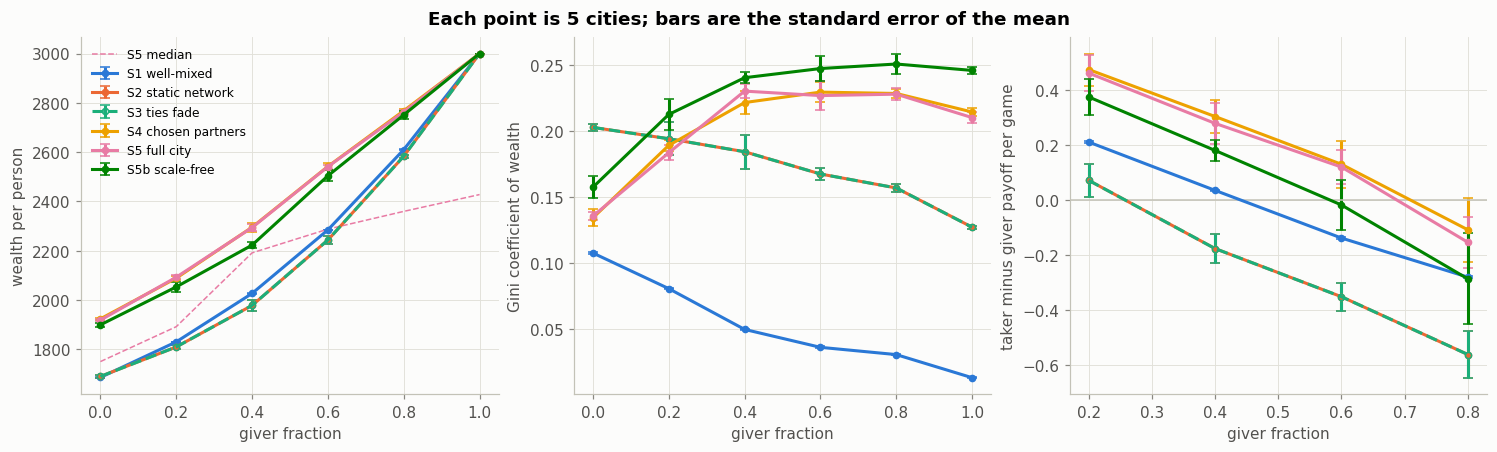

gini                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.0                    0.108             0.203        0.203   
0.2                    0.081             0.194        0.194   
0.4                    0.050             0.184        0.184   
0.6                    0.036             0.168        0.168   
0.8                    0.031             0.157        0.157   
1.0                    0.013             0.127        0.127   

                                                                mean_wealth  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.0                         0.134        0.136          0.158      1686.050   
0.2                         0.189        0.184          0.213      1830.362   
0.4                         0.222        0.230          0.241      2026.800   
0.6                         0.230        0.227          0.248      2284.600   
0.8                         0.229        0.228          0.251      2610.214   
1.0                         0.215        0.210          0.246      3000.000   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.0                     1690.078     1690.078           1923.750     1918.346   
0.2                     1809.714     1809.714           2088.758     2092.656   
0.4                     1978.160     1978.160           2295.462     2294.066   
0.6                     2243.618     2243.618           2541.958     2540.986   
0.8                     2583.390     2583.390           2768.052     2763.264   
1.0                     3000.000     3000.000           3000.000     3000.000   

                               
scenario       S5b scale-free  
giver_fraction                 
0.0                  1899.370  
0.2                  2053.278  
0.4                  2222.834  
0.6                  2504.038  
0.8                  2751.082  
1.0                  3000.000

In [6]:
means = R.cell_means(runs, ["mean_wealth", "median_wealth", "gini", "coop_rate", "payoff_gap"])
colours = dict(zip(SCENARIOS, P.SERIES))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
panels = [("mean_wealth", "wealth per person"), ("gini", "Gini coefficient of wealth"),
          ("payoff_gap", "taker minus giver payoff per game")]
for ax, (metric, label) in zip(axes, panels):
    for name in BASE:
        rows = means[means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name,
                    linestyle=LINESTYLE.get(name, "-"), mfc="none" if name in LINESTYLE else None)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].plot(means[means["scenario"] == "S5 full city"]["giver_fraction"],
             means[means["scenario"] == "S5 full city"]["median_wealth"],
             color=colours["S5 full city"], linewidth=1, linestyle="--", label="S5 median")
axes[2].axhline(0, color=P.AXIS, linewidth=1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Each point is {N_SEEDS} cities; bars are the standard error of the mean", fontweight="bold")
P.save(fig, "sweep")
plt.show()

means[means["scenario"].isin(BASE)].pivot_table(index="giver_fraction", columns="scenario", values=["mean_wealth", "gini"]).round(3)

> **Insight 1, prosperity rises faster than the share of givers:** a giver only creates its full surplus when it meets another giver, so wealth per person bends upwards as givers become common (H1, tested below).
>
> **Real life or model?** The shape is what the payoff matrix implies, and it matches the context dependence of real cooperation [1]: the same norm pays off where enough others share it. The *location* of the bend is a property of the model, set by the payoffs and by who can meet whom, so it should not be read as a real-world threshold.

### Who Ends Up Connected to Whom

S2 and S3 produce identical cities, so S3 is drawn dashed, with open markers, on top of S2.

**The figure:** two panels for mixed cities (giver fraction 0.2 to 0.8). Left: class assortativity of the network at week 500, where positive means givers are tied mostly to givers and negative means the classes are mixed more than chance. Right: the number of distinct partners a taker played in the last 100 weeks minus the number a giver played, so negative means takers are met by fewer people.

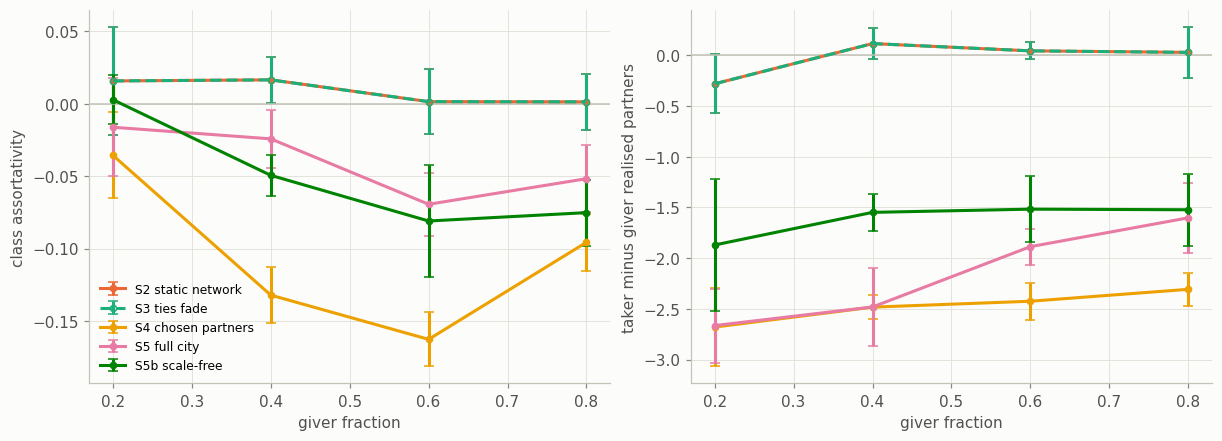

assortativity_class                                 \
scenario             S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                      
0.2                          -0.01             0.016        0.016   
0.4                          -0.01             0.017        0.017   
0.6                          -0.01             0.002        0.002   
0.8                          -0.01             0.001        0.001   

                                                                partner_gap  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.2                        -0.036       -0.016          0.003         0.512   
0.4                        -0.132       -0.024         -0.049        -0.425   
0.6                        -0.163       -0.069         -0.081         0.125   
0.8                        -0.096       -0.052         -0.075         0.075   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.2                       -0.280       -0.280             -2.680       -2.665   
0.4                        0.117        0.117             -2.483       -2.482   
0.6                        0.045        0.045             -2.425       -1.887   
0.8                        0.030        0.030             -2.308       -1.602   

                               
scenario       S5b scale-free  
giver_fraction                 
0.2                    -1.870  
0.4                    -1.548  
0.6                    -1.517  
0.8                    -1.523

In [7]:
structure = runs.assign(partner_gap=runs["realised_degree_taker"] - runs["realised_degree_giver"],
                        weight_gap=runs["weight_taker"] - runs["weight_giver"])
mixed = structure[structure["giver_fraction"].between(0.15, 0.85)]
struct_means = R.cell_means(mixed, ["assortativity_class", "partner_gap", "weight_gap"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, (metric, label) in zip(axes, [("assortativity_class", "class assortativity"),
                                      ("partner_gap", "taker minus giver realised partners")]):
    for name in ["S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S5b scale-free"]:
        rows = struct_means[struct_means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name,
                    linestyle=LINESTYLE.get(name, "-"), mfc="none" if name in LINESTYLE else None)
    ax.axhline(0, color=P.AXIS, linewidth=1)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].legend(fontsize=8, loc="lower left")
plt.show()

struct_means[struct_means["scenario"].isin(BASE)].pivot_table(index="giver_fraction", columns="scenario",
                         values=["assortativity_class", "partner_gap"]).round(3)

> **Insight 2, without refusal takers cling to givers:** the city becomes slightly disassortative, because takers seek out the best-rated citizens, who are givers.
>
> **Real life or model?** Mostly the model. In experiments, people who are allowed to cut ties break them with defectors and seek out cooperators (Insight 7), so real cities would sort the other way. Our givers cannot decline a game until S6, and the next sections show that this one assumption is what produces the mixing.

## Results and Discussion

### What the plots show

**Prosperity (H1):** wealth per person rises with the giver share in every scenario, from roughly 1,700 to 3,000. The rise is not a straight line: it is shallow while takers dominate and steeper once givers are common, because an extra giver only creates surplus when there is another giver to meet. In the well-mixed city (S1), inequality is the lowest of any scenario at every mix, since meeting everyone with equal probability gives no citizen a structural edge.

**Structure changes who wins (S1 to S2):** putting the same population on a fixed network raises inequality sharply and turns the taker payoff advantage negative at moderate giver shares: with repeated meetings, reciprocal strategies punish the takers they can recognise. This is network reciprocity, and it is visible as the gap between the S1 and S2 curves.

**Neglect alone has no effect here (S2 to S3):** not one tie breaks in any S3 city: with about six neighbours and a meeting every week, a tie is used long before it could decay past the threshold. Wealth, cooperation and inequality are therefore identical to S2, run for run; only the tie strengths differ, because decay keeps them bounded instead of letting them accumulate indefinitely. Decay also cannot tell a giver from a taker while partners are drawn uniformly.

**Choice separates the classes (S3 to S4):** once meetings depend on proximity, habit and popularity, inequality rises by about a fifth at `f = 0.4` and by about 40% at `f = 0.6` and above, and takers end with two to three fewer realised partners than givers out of roughly ten. Most of the inequality in the full model appears at this step.

**Rewiring repairs without redistributing (S4 to S5):** refilling severed ties leaves wealth, cooperation and inequality within a few percent of S4, because new ties are drawn by the same rule that already favoured the same citizens. It does more than halve the class disassortativity, since a refilled tie is a fresh draw rather than a surviving habit.

**Hubs concentrate the gains (S5b):** on the scale-free network inequality is the highest of any scenario without refusal and stays high in giver-dominated cities, where the other networks are becoming more equal again.

**Refusal turns exploitation into exclusion (S5 to S6):** once citizens walk away from anyone who cheats them, almost every taker ends the run with no ties at all. Givers keep about 3,000 each at every mix, takers fall to a few hundred, and the city as a whole is poorer wherever takers are common, because a citizen nobody will meet produces nothing. *The Right to Refuse* below has the numbers.

### Why these patterns make sense

1. **Cooperation is a joint product:** two givers create six units of wealth; a giver and a taker create five, most of it going to the taker; two takers create two. Prosperity therefore tracks the *rate of giver-giver meetings*, which grows faster than the giver share itself. That is the threshold in H1.

2. **Inequality needs a mechanism, and here it is access:** in the well-mixed city everyone meets everyone, and inequality stays low. Adding a network, then habit, then status, each narrows who a citizen can reach, and each raises inequality. The gains of cooperation flow to whoever is met most.

3. **Without refusal, takers are not shunned, they are dropped by each other:** class assortativity is negative, not positive: the popularity rating points everyone, takers included, towards cooperative givers, and givers cannot refuse. Ties between two takers are the ones nobody uses, so they decay and break. Takers end up clinging to the givers they exploit, with fewer partners and weaker ties. Give the givers the right to refuse (S6) and this reverses completely.

4. **The richest cities are not the most equal:** inequality peaks in mixed cities, where both classes are present and the gap between them is widest. Whether it falls again depends on the network: on a random network it does, as takers disappear; on a scale-free network hubs keep collecting meetings, so it stays high.

## Hypothesis Check

Each hypothesis is tested on the full-city scenario (S5) with the decision rules fixed before the runs: a two-segment fit against a straight line for H1 [12], [13]; percentile bootstrap intervals over seeds for the rest [14].

In [8]:
from utilities import stats as S


def hypothesis_table(scenario):
    full = runs[runs["scenario"] == scenario].rename(columns={"giver_fraction": "population.giver_fraction"})
    # A fresh stream per test, so each verdict depends only on the runs and its own seed.
    h1 = S.h1_threshold(full, rng=np.random.default_rng(1))
    h2 = S.h2_decoupling(full, rng=np.random.default_rng(2))
    h3 = S.h3_segregation(full, fractions=FRACTIONS[1:-1], rng=np.random.default_rng(3))
    h4 = S.h4_equal_poverty(full, rng=np.random.default_rng(4))
    return pd.DataFrame([
        {"hypothesis": "H1 prosperity threshold", "test": "two-segment fit beats a line, steeper above the break",
         "result": f"BIC difference {h1['delta_bic']:.0f}, break at f = {h1['break']:.2f}", "verdict": h1["verdict"]},
        {"hypothesis": "H2 prosperity and equality decouple", "test": "Gini and wealth rise together above f = 0.5",
         "result": f"Spearman(f, Gini) = {h2['spearman']:.2f}", "verdict": h2["verdict"]},
        {"hypothesis": "H3 emergent segregation", "test": "assortativity rises; takers keep fewer, weaker ties",
         "result": f"assortativity slope {h3['slope'][0]:.1e}, partner gap {h3['degree_gap'][0]:.2f}, weight gap {h3['weight_gap'][0]:.2f}",
         "verdict": h3["verdict"]},
        {"hypothesis": "H4 the poverty trap is equal", "test": "taker cities poorer, not more unequal",
         "result": f"median wealth gap {h4['median_gap'][0]:.0f}, Gini gap {h4['gini_gap'][0]:.3f}", "verdict": h4["verdict"]},
    ]).set_index("hypothesis")


with pd.option_context("display.max_colwidth", 90):
    display(hypothesis_table("S5 full city"))
# The same decision rules on the city whose citizens can refuse, for comparison in the next sections.
hypothesis_table("S6 refusal")[["result", "verdict"]]

,test,result,verdict
hypothesis,,,
H1 prosperity threshold,"two-segment fit beats a line, steeper above the break","BIC difference 18, break at f = 0.29",supported
H2 prosperity and equality decouple,Gini and wealth rise together above f = 0.5,"Spearman(f, Gini) = 0.56",inconclusive
H3 emergent segregation,"assortativity rises; takers keep fewer, weaker ties","assortativity slope -9.3e-05, partner gap -2.16, weight gap -3.87",inconclusive
H4 the poverty trap is equal,"taker cities poorer, not more unequal","median wealth gap -573, Gini gap -0.060",supported


,result,verdict
hypothesis,,
H1 prosperity threshold,"BIC difference 91, break at f = 0.50",inconclusive
H2 prosperity and equality decouple,"Spearman(f, Gini) = -0.14",inconclusive
H3 emergent segregation,"assortativity slope nan, partner gap -6.68, we...",inconclusive
H4 the poverty trap is equal,"median wealth gap -2091, Gini gap 0.049",refuted


**Reading the verdicts:** the first table is the full city (S5), which the hypotheses were written for. H1 and H4 are supported; H2 and H3 are inconclusive, for different reasons.

- **H1 is supported:** the two-segment fit beats a straight line (BIC difference 18, above the threshold of 10), and the bend sits at a giver share of 0.29, well below a 50/50 mix.
- **H2 is inconclusive:** inequality is *hump-shaped* in the giver share, not monotone in either direction. The Gini climbs steeply while takers dominate (+0.048 and +0.046 over the first two steps), is flat through the middle (-0.003 from 0.4 to 0.6 and +0.001 from 0.6 to 0.8), then *falls* at the top (-0.018 from 0.8 to 1.0). H2's supporting criterion asks inequality and wealth to rise **together** above f = 0.5, and they do not. Its refuting criterion asks the Gini to fall with the giver share, and it does not do that either (Spearman 0.56 overall). So H2 is right that prosperity and equality decouple, and wrong about where: the decoupling is in the middle of the range, not at the top.
- **H3 is inconclusive because its two halves disagree:** takers do end up with fewer partners (a gap of -2.2) and weaker ties (-3.9), but class assortativity is negative and its slope over the last 100 weeks is indistinguishable from zero (-9.3e-05). The exclusion H3 predicted is real; the sorting is not.
- **H4 is supported:** taker-dominated cities are poorer (median wealth gap -573) and more equal (Gini gap -0.060).

**The same tests on S6** (second table) come out differently, and the sections below explain why:

- **H1 is not supported:** wealth still beats a straight line on BIC, but it bends the wrong way. Each extra 20% of givers adds less than the one before (637, 601, 559, 520 and 478 per person), so there is no threshold to cross: a giver who can walk away from takers finds other givers however scarce they are.
- **H4 is refuted:** taker-dominated cities under refusal are poorer (median wealth gap -2,091) and *more* unequal (Gini gap +0.049), because the few givers in them stay rich while the many takers are shut out.
- **H3 cannot be scored on S6:** class assortativity is undefined once takers hold no ties at all, which is the strongest form of the exclusion H3 describes.

## Extended Analysis

The sweep above reports each city by its final state. That is the right summary for a hypothesis
test, but it discards three things worth looking at: how a city got where it ended up, what each
mechanism contributed on the way, and what the network looked like while it happened.

This section re-reads the same 210 runs, and asks five questions:

1. **What converges, and what cannot?** A steady state here is a claim about flows, not stocks.
2. **Where do the scenarios actually diverge?** The ladder adds one mechanism per step, so each
   step's contribution can be measured rather than argued from the curves.
3. **Does the city cluster?** H2 rests on the claim that cooperation depends on clusters, and
   nothing in the model has so far measured one.
4. **Where does inequality come from when nobody is ever exploited?**
5. **What changes when citizens can refuse?** S6 against S5, how long a refusal should last, what
   the Gini misses, and a taker that is harder to spot.

### What Converges, and What Cannot

A steady state in this model cannot mean that wealth stops changing. Wealth is a stock that only
accumulates: with no spending and no depreciation, mean wealth rises for as long as the
simulation runs, by construction rather than by result. A convergence test applied to it would
fail forever, however settled the city was.

What can settle is the **flow**: how much income is produced per week, and how unevenly it is
shared. That is why `steady_state` in `source/experiment.py` tests the slope of rolling income
Gini and of mean income rather than of wealth. The figure below is that distinction made visible.

**The figure:** four panels for cities at `f = 0.6`, each plotted against the week. Each line is a scenario's mean over seeds, with a band of one standard error. From left: wealth per person, a stock that accumulates; the Gini of that wealth; the Gini of income over the last 25 weeks, a flow; and the share of moves that were cooperative.

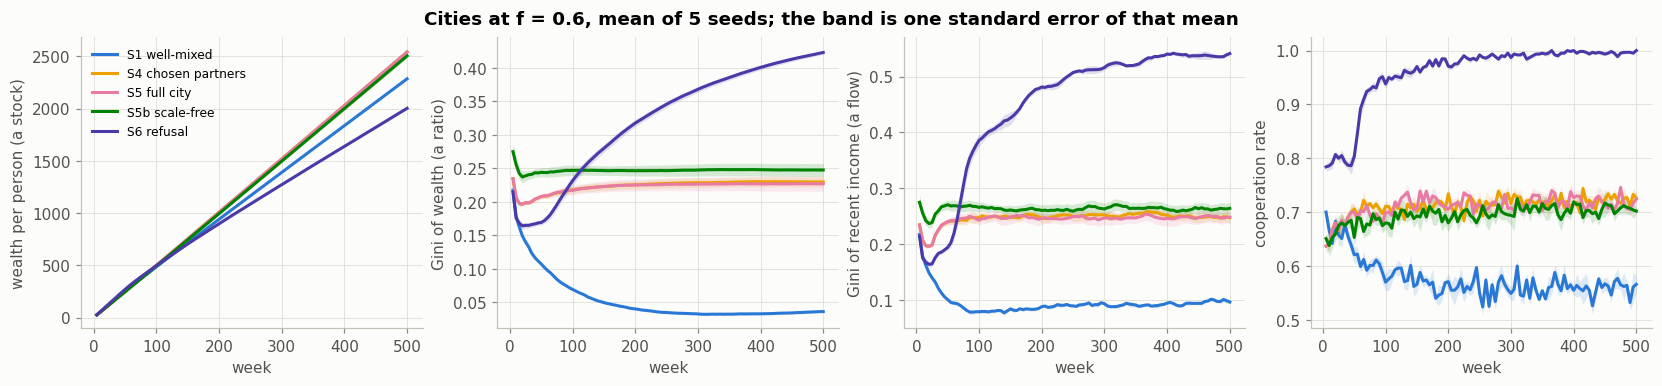

gini        income_gini        mean_wealth          
round                 250    500         250    500         250       500
scenario                                                                 
S1 well-mixed       0.035  0.036       0.090  0.097    1165.038  2284.600
S2 static network   0.168  0.168       0.179  0.188    1123.670  2243.618
S3 ties fade        0.168  0.168       0.179  0.188    1123.670  2243.618
S4 chosen partners  0.227  0.230       0.250  0.248    1262.682  2541.958
S5 full city        0.226  0.227       0.249  0.248    1263.444  2540.986
S5b scale-free      0.247  0.248       0.259  0.264    1244.964  2504.038
S6 refusal          0.346  0.423       0.507  0.541    1086.014  2002.224

In [9]:
LADDER = ["S1 well-mixed", "S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S6 refusal"]
SHOWN = ["S1 well-mixed", "S4 chosen partners", "S5 full city", "S5b scale-free", "S6 refusal"]

# One giver fraction at a time: averaging across the mix would blend cities that differ by design.
mid_core = sweep.core[np.isclose(sweep.core["giver_fraction"], 0.6)]
convergence = R.series_means(mid_core, ["mean_wealth", "gini", "income_gini", "coop_rate"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
panels = [("mean_wealth", "wealth per person (a stock)"), ("gini", "Gini of wealth (a ratio)"),
          ("income_gini", "Gini of recent income (a flow)"), ("coop_rate", "cooperation rate")]
for ax, (metric, label) in zip(axes, panels):
    P.over_time(ax, convergence, metric, SHOWN, colours, ylabel=label)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Cities at f = 0.6, mean of {N_SEEDS} seeds; the band is one standard error of that mean",
             fontweight="bold")
plt.show()

convergence[convergence["round"].isin([250, 500])].pivot_table(
    index="scenario", columns="round", values=["mean_wealth", "gini", "income_gini"]).round(3)

**What this shows:** mean wealth doubles between week 250 and week 500 in every scenario (S5: 1,263 to 2,541), which is what a stock with a constant inflow must do. It never converges and never will. In the first five steps every other panel is flat well before the end: in S5 the Gini of wealth moves from 0.226 to 0.227 over those same 250 weeks, and the Gini of recent income from 0.249 to 0.248.

So the cities of S1 to S5 *are* in a steady state by week 250, in the only sense the word can have here: the rate at which wealth is produced and the unevenness of its sharing have both stopped changing. S6 is the exception. Takers are still being shut out in the second half of the run, so its Gini of income is still rising (0.507 to 0.541) and its results are a snapshot of a city still sorting itself, not of a settled one. This is also the justification for summarising flow metrics over the last 100 rounds and stocks by their final value, which is what `summarise` does and what every table above reports.

> **Insight 3, flows settle, stocks do not:** income and its inequality stop changing by week 250 in S1 to S5, while wealth keeps growing.
>
> **Real life or model?** The model. Wealth here is never spent, so it can only grow; real economies consume and depreciate. This is why results are read from flows over the last 100 weeks and from final stocks, never from a stock's trend.

### Where the Scenarios Diverge

The ladder is built so that each step adds exactly one mechanism, and every scenario shares its
random streams with the others for a given seed. That makes a **paired** comparison possible: for
each of the 30 cities (6 giver fractions x 5 seeds) we can take the same city under two adjacent
rule sets and difference them. What is left is the mechanism, with the luck of the draw cancelled
out.

This is the quantitative version of the S1-to-S6 story told in the results section above, and on
two points it corrects it.

**The figure:** each row is one step of the model, from the step before to the step after, and each bar is the mean change in one measure across the same cities run under both rule sets. Blue bars are increases and orange are decreases; whiskers are one standard error. From left: wealth per person, Gini of wealth, cooperation rate, and taker minus giver payoff per game.

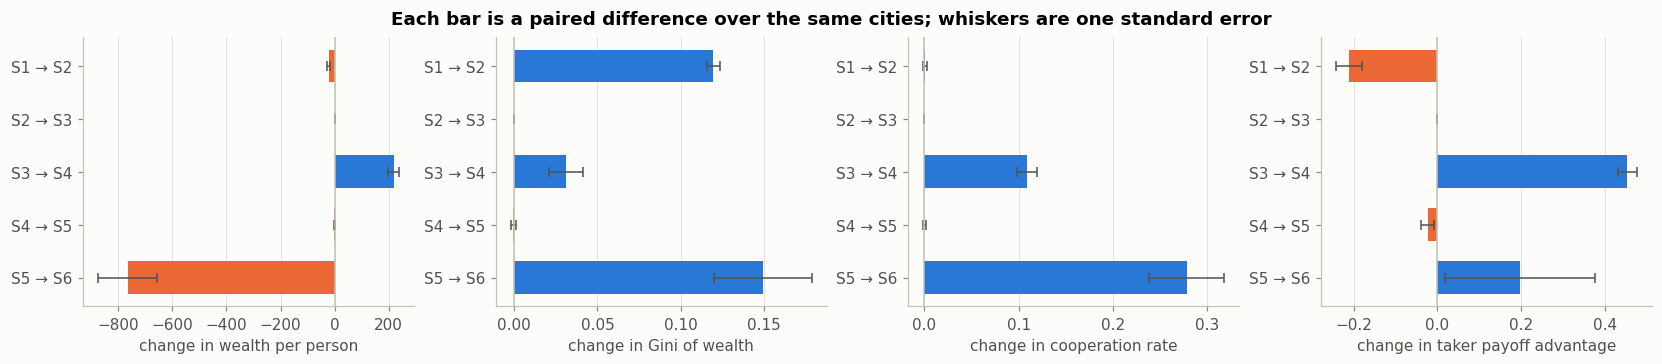

,metric,step,mean,se,n
0,mean_wealth,S1 → S2,-22.1777,5.7402,30
1,mean_wealth,S2 → S3,0.0000,0.0000,30
2,mean_wealth,S3 → S4,218.8367,20.0821,30
3,mean_wealth,S4 → S5,-1.4437,1.7096,30
4,mean_wealth,S5 → S6,-765.8300,108.6873,30
0,gini,S1 → S2,0.1194,0.0038,30
1,gini,S2 → S3,0.0000,0.0000,30
2,gini,S3 → S4,0.0308,0.0102,30
3,gini,S4 → S5,-0.0005,0.0016,30
4,gini,S5 → S6,0.1492,0.0294,30


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
panels = [("mean_wealth", "change in wealth per person"), ("gini", "change in Gini of wealth"),
          ("coop_rate", "change in cooperation rate"), ("payoff_gap", "change in taker payoff advantage")]
deltas = {}
# payoff_gap is undefined when a class is absent, so its panel pairs only the mixed cities.
for ax, (metric, label) in zip(axes, panels):
    deltas[metric] = R.stage_deltas(runs, metric, LADDER)
    P.delta_bars(ax, deltas[metric], xlabel=label)
fig.suptitle("Each bar is a paired difference over the same cities; whiskers are one standard error",
             fontweight="bold")
P.save(fig, "ladder_deltas")
plt.show()

pd.concat([t.assign(metric=m) for m, t in deltas.items()])[["metric", "step", "mean", "se", "n"]].round(4)

**What this shows, and where it revises the story above:**

- **Structure redistributes without creating:** Putting the same population on a fixed network (S1 to S2) raises the Gini by 0.119 and *lowers* wealth per person slightly (-22, se 6). The taker payoff advantage falls by 0.211 per game, which is network reciprocity working as expected. But the cooperation rate does not move (+0.0008, se 0.0019). Network reciprocity here changes the distribution of a fixed amount of cooperation, not the amount.

- **Choice is where almost everything happens without refusal:** S3 to S4 adds +219 to wealth per person, +0.109 to the cooperation rate and +0.031 to the Gini. It also *reverses* the taker payoff advantage, adding back 0.454 per game. The reason is below: choice does not change how a taker plays; it changes who it plays.

- **S2 to S3 is exactly zero on every measure in this table:** Not approximately: the paired difference and its standard error are both 0.0000, because no tie in any S3 city ever decays past the severance threshold. With about six neighbours and a meeting every week, a tie is used every few weeks, long before the 46 weeks it would take to fade away. Fading still changes the *strength* of ties, which S2 lets grow without limit and S3 pulls back every week, and tie strength is what the choice rule weighs in S4. So decay is not a mechanism that does nothing; it is one that does nothing **yet**.

- **Rewiring repairs rather than redistributes:** S4 to S5 moves wealth by -1.4 and the Gini by -0.0005, neither distinguishable from zero.

- **Refusal is the second large step:** S5 to S6 removes 766 from wealth per person (se 109), adds 0.149 to the Gini (se 0.029) and 0.278 to the cooperation rate. Cooperation rises because the games that still happen are almost all between givers; wealth falls because far fewer games happen at all.

In [11]:
# Choice does not change how a taker plays; it changes who it plays. Every citizen weighs
# candidates by the partner's rating, and givers are the ones with high ratings.
def partner_mix_once(stage_name, repeat):
    cfg = stage(stage_name, **{**SETTINGS, "population.giver_fraction": 0.5})
    sim = Simulation(cfg, root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    giver = sim.state.giver
    played = np.zeros((2, 2))                              # [actor is a giver, partner is a giver]
    for _ in range(cfg.run.n_rounds):
        record = sim.run_round().record
        if record.n_games == 0:
            continue
        gi, gj = giver[record.initiator], giver[record.partner]
        for actor, partner in ((gi, gj), (gj, gi)):        # both sides of every game
            for cls in (0, 1):
                played[cls, 1] += ((actor == bool(cls)) & partner).sum()
                played[cls, 0] += ((actor == bool(cls)) & ~partner).sum()
    share = played / played.sum(axis=1, keepdims=True)
    return {"a taker's games that are against givers": share[0, 1],
            "a giver's games that are against givers": share[1, 1],
            "mean popularity rating, givers": sim.state.rating[giver].mean(),
            "mean popularity rating, takers": sim.state.rating[~giver].mean()}


# The same seeds as the sweep, so these numbers carry their uncertainty like the rest.
def partner_mix(stage_name, n_seeds=N_SEEDS):
    seeds = pd.DataFrame([partner_mix_once(stage_name, repeat) for repeat in range(n_seeds)])
    return pd.DataFrame({"mean": seeds.mean(), "se": seeds.sem()})

mix = pd.concat({"S3 uniform draws": partner_mix("M2"),
                 "S4 chosen partners": partner_mix("M3")}, axis=1)
mix.round(3)

S3 uniform draws         \
                                                    mean     se   
a taker's games that are against givers            0.487  0.014   
a giver's games that are against givers            0.507  0.015   
mean popularity rating, givers                     1.000  0.000   
mean popularity rating, takers                     1.000  0.000   

                                        S4 chosen partners         
                                                      mean     se  
a taker's games that are against givers              0.764  0.012  
a giver's games that are against givers              0.594  0.008  
mean popularity rating, givers                       0.511  0.006  
mean popularity rating, takers                       0.166  0.003

**Who a taker gets to play:** under uniform draws both classes face the mix you would expect by
chance, near 50/50 (a taker 0.487, a giver 0.507). Once meetings are chosen, a taker plays **76%**
of its games against givers, while a giver plays 59% of its games against other givers. Nobody
wrote a rule sending takers towards cooperators: every citizen weighs candidates by the partner's
rating, givers earn ratings three times higher than takers (0.511 against 0.166), and so everyone
steers the same way. Takers steer there too, and **givers cannot refuse**: a giver has no means
of declining a partner that defected on it last week, only of defecting back. All figures are
means over the same seeds as the sweep, and the standard errors are in the table.

Defecting on a cooperator pays `T = 5`, the largest payoff in the game, so a diet three-quarters
made of cooperators is what lifts the taker payoff advantage by 0.454 at this step.

Both classes still *initiate* half the meetings, because every citizen starts exactly one per week.
The asymmetry is not in who reaches out; it is in who they reach for, and in who has to accept.
This is also the mechanism behind the negative class assortativity reported above, and the reason
for S6, which gives givers the right to refuse.

> **Insight 4, who meets whom matters more than the network or the population:** putting a city on a network redistributes wealth without creating any, fading ties change nothing yet, and partner choice produces most of the change in prosperity, cooperation and inequality.
>
> **Real life or model?** Real data point the same way: who people are connected to predicts economic mobility better than how cohesive their networks are [2]. The null effect of fading ties is a quirk of the settings: a tie used every few weeks never comes near the 46 weeks it needs to fade.

### Clustering and Connectivity

H2 argues that inequality does not fall with cooperation partly because "cooperation relies on
clusters". Up to this point that claim was carried entirely by the citations: no measurement in
this notebook said anything about clustering. Two coefficients fix that.

**Average clustering** is the mean over citizens of the share of their acquaintance pairs who
also know each other, so it reports the typical citizen. **Transitivity** is closed triples over
all triples across the whole city, which weights by degree and so reports the city. Both are
tracked every 10 weeks alongside the mean shortest path and the number of components.

One caution has to come before any number. The claim in the literature is **evolutionary**:
cooperators who cluster shield one another from defectors, do better on average, and are then
imitated or reproduced, so cooperation spreads. Our citizens are assigned a strategy in week 0
and never change it, and nobody ever copies anyone. That mechanism cannot run in this model at
all, so nothing measured here can confirm or refute H2's premise on its own terms.

It also means a correlation between clustering and cooperation *across the sweep* would be
worthless as evidence. The sweep varies the giver fraction, and the giver fraction sets the
cooperation rate almost by itself; pooling cities with different mixes would mostly measure the
population, not the wiring. What the model can answer is the narrower question: holding the
population fixed, does the **arrangement** of the same ties matter? That has a clean test, and
it is run below.

**The figure:** three panels for cities at `f = 0.6`, plotted against the week. Left: the average clustering coefficient, the share of a citizen's pairs of acquaintances who also know each other. Centre: the mean shortest path between citizens who can still reach each other. Right: clustering for givers and takers separately, in S4.

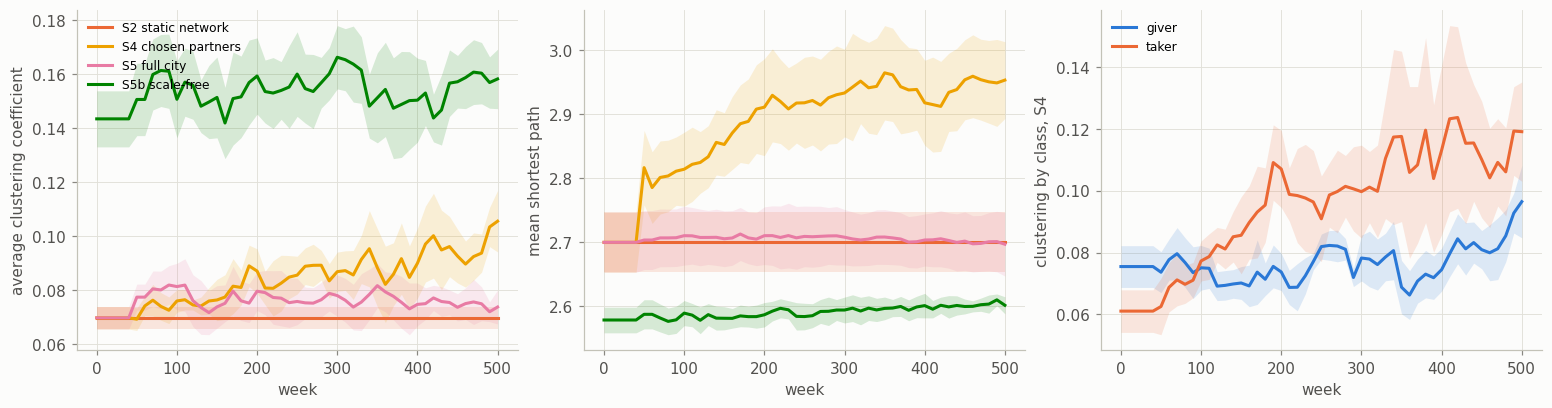

clustering        mean_path_length        n_components  \
round                     0      500              0      500          0     
scenario                                                                    
S1 well-mixed           1.000  1.000            1.000  1.000          1.0   
S2 static network       0.070  0.070            2.699  2.699          1.0   
S3 ties fade            0.070  0.070            2.699  2.699          1.0   
S4 chosen partners      0.070  0.105            2.699  2.953          1.0   
S5 full city            0.070  0.074            2.699  2.696          1.0   
S5b scale-free          0.143  0.158            2.578  2.601          1.0   
S6 refusal              0.070  0.065            2.699  2.453          1.0   

                          
round                500  
scenario                  
S1 well-mixed        1.0  
S2 static network    1.0  
S3 ties fade         1.0  
S4 chosen partners   1.4  
S5 full city         1.0  
S5b scale-free       1.0  
S6 refusal          39.8

In [12]:
mid_structure = sweep.structure[np.isclose(sweep.structure["giver_fraction"], 0.6)]
structure_ts = R.series_means(mid_structure, ["clustering", "clustering_giver", "clustering_taker",
                                              "transitivity", "mean_path_length", "n_components"])
NETWORKS = ["S2 static network", "S4 chosen partners", "S5 full city", "S5b scale-free"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
P.over_time(axes[0], structure_ts, "clustering", NETWORKS, colours,
            ylabel="average clustering coefficient")
P.over_time(axes[1], structure_ts, "mean_path_length", NETWORKS, colours,
            ylabel="mean shortest path")
s4 = structure_ts[structure_ts["scenario"] == "S4 chosen partners"].sort_values("round")
for column, label in [("clustering_giver", "giver"), ("clustering_taker", "taker")]:
    P.band(axes[2], s4["round"], s4[column], s4[column] - s4[f"{column}_se"],
           s4[column] + s4[f"{column}_se"], P.CLASS_COLOURS[label], label=label)
axes[2].set(xlabel="week", ylabel="clustering by class, S4")
axes[0].legend(fontsize=8, loc="upper left")
axes[2].legend(fontsize=8)
plt.show()

# The path length is reported next to the component count deliberately. It averages only over
# pairs that can still reach each other, so a city that breaks apart can post a *shorter* mean
# path simply by dropping its longest routes from the average. The two have to be read together.
edges = structure_ts[structure_ts["round"].isin([0, structure_ts["round"].max()])]
edges.pivot_table(index="scenario", columns="round",
                  values=["clustering", "mean_path_length", "n_components"]).round(3)

**Turning clustering up and down directly:** the Watts-Strogatz model interpolates
between a ring lattice and a random graph with one rewiring probability `p`, holding the mean
degree at 6 the whole way. At `p = 0` every citizen sits in a tight neighbourhood and clustering
is 0.60; at `p = 1` the wiring is essentially random and clustering is 0.05. Running the same
population across that dial separates the arrangement of ties from the mix of people, which is
exactly what the sweep could not do.

The test has to be run on **S2**, the static network, because that is the only scenario where the
setting survives. In S4 and S5 the city rewrites its own ties, and by week 500 an S5 city that
started as a lattice ends with almost the same clustering as one that started random (left panel
below). That is worth knowing on its own: in the full model the city's tie dynamics overwrite whatever
clustering it was handed, so clustering there is an outcome rather than a condition.

**The figure:** the same population at `f = 0.5` on Watts-Strogatz networks, from a ring lattice (`p = 0`) to a random graph (`p = 1`). Left: clustering at week 500 against the rewiring probability `p`, for S2 and S5. Centre and right: S2's cooperation rate and Gini against its clustering. Their vertical ranges are set to the size of the change partner choice produces (0.11), so a flat line means an effect small by that standard.

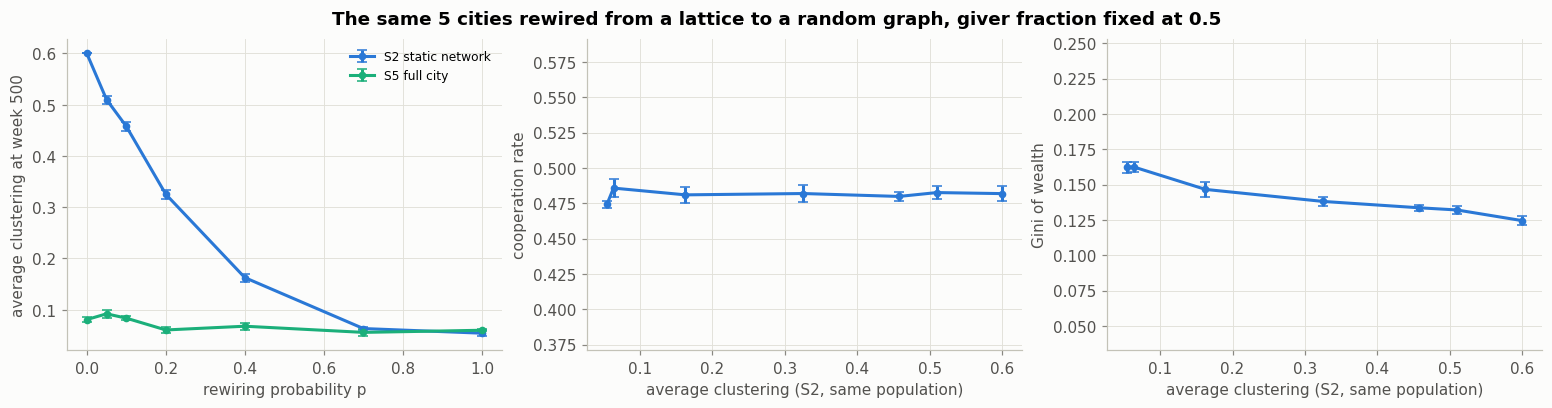

,lattice (p = 0),random (p = 1),paired change,se
metric,,,,
clustering,0.6000,0.0542,-0.5458,0.0056
coop_rate,0.4818,0.4743,-0.0075,0.0066
gini,0.1245,0.1623,0.0378,0.0038


In [13]:
# One population, one mean degree, one giver fraction: only the arrangement of ties changes.
REWIRE = [0.0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
WS_SCENARIOS = {f"{label}|{p}": (base, {"topology.name": "watts_strogatz",
                                        "topology.ws_rewire_prob": p})
                for label, base in [("S2 static network", "M1"), ("S5 full city", "M4")]
                for p in REWIRE}
ws = R.sweep(WS_SCENARIOS, [0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)
ws["stage"] = ws["scenario"].str.split("|").str[0]
ws["rewire"] = ws["scenario"].str.split("|").str[1].astype(float)
dial = R.cell_means(ws, ["clustering", "coop_rate", "gini"], by=("stage", "rewire"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for stage_label, colour in zip(["S2 static network", "S5 full city"], [P.SERIES[0], P.SERIES[2]]):
    rows = dial[dial["stage"] == stage_label].sort_values("rewire")
    axes[0].errorbar(rows["rewire"], rows["clustering"], yerr=rows["clustering_se"],
                     color=colour, marker="o", markersize=4, capsize=3, label=stage_label)
axes[0].set(xlabel="rewiring probability p", ylabel="average clustering at week 500")
axes[0].legend(fontsize=8)

static = dial[dial["stage"] == "S2 static network"].sort_values("clustering")
# The y range is set to the size of the effect that partner choice produced (+0.110 cooperation),
# so that "flat" is read against something rather than against the width of the axis.
for ax, metric, label, span in [(axes[1], "coop_rate", "cooperation rate", 0.11),
                                (axes[2], "gini", "Gini of wealth", 0.11)]:
    ax.errorbar(static["clustering"], static[metric], yerr=static[f"{metric}_se"],
                color=P.SERIES[0], marker="o", markersize=4, capsize=3)
    centre = static[metric].mean()
    ax.set(xlabel="average clustering (S2, same population)", ylabel=label,
           ylim=(centre - span, centre + span))
fig.suptitle(f"The same {N_SEEDS} cities rewired from a lattice to a random graph, giver "
             "fraction fixed at 0.5", fontweight="bold")
plt.show()

paired = ws[ws["stage"] == "S2 static network"].pivot_table(
    index="repeat", columns="rewire", values=["clustering", "coop_rate", "gini"])
pd.DataFrame([{"metric": m, "lattice (p = 0)": paired[m][0.0].mean(),
               "random (p = 1)": paired[m][1.0].mean(),
               "paired change": (paired[m][1.0] - paired[m][0.0]).mean(),
               "se": (paired[m][1.0] - paired[m][0.0]).sem()}
              for m in ["clustering", "coop_rate", "gini"]]).set_index("metric").round(4)

**What this shows:**

- **Severance concentrates, rewiring restores reach:** In S4, where ties break and are never
  replaced, clustering rises from 0.070 to 0.105 while the mean shortest path stretches from 2.70
  to 2.95 and the city splits into 1.4 components on average. Those two numbers belong in the
  same sentence: the mean path length is taken over reachable pairs only, so a fragmenting city
  can post a *shorter* path by dropping its longest routes out of the average entirely. Here the
  path grows despite that, which makes the stretching real rather than an artefact. In S5 the same
  severance happens, but refilled ties are drawn from distance 2 and 3, so clustering barely moves
  (0.070 to 0.074), the path holds at 2.70, and the city stays in exactly one piece. S6 is the
  extreme case: its takers are cut off one by one, so the city ends in about 40 components, almost
  all of them single citizens with no ties.

- **Clustering barely moves cooperation:** Collapsing clustering from 0.600 to 0.054 (an
  elevenfold change, with the same citizens, the same mean degree and the giver fraction pinned at
  0.5) moves the cooperation rate by -0.0075, with a standard error of 0.0066: not distinguishable
  from zero at this seed count, and at most a fourteenth of the +0.109 that partner choice delivers
  at a single step of the ladder. Within what this model can express, how ties are arranged matters
  far less than who gets chosen.

  The result is narrow. It does not refute the literature, because
  the mechanism the literature proposes cannot occur here: no citizen ever changes strategy, so
  clustered cooperators can never out-reproduce anyone. **H2 should not rest on clustering** in
  this project. It should rest on access and status, which the decomposition above does support.

- **Inequality moves along the dial too, but the cause is not clean:** The same rewiring raises
  the Gini by +0.038 (se 0.004), from 0.125 in the lattice to 0.162 in the random graph. The
  tempting reading is that clustering protects the poor. The careful one is that Watts-Strogatz
  rewires one end of each edge, so it also spreads the degrees, from exactly 6 for every citizen
  at `p = 0` to an uneven spread at `p = 1`. Capacity is pinned at the starting degree, so that
  spread is itself unequal access. This design cannot separate the two, and we do not claim it
  does, but both readings point the same way as the rest of the project: inequality tracks who can
  be met, not who defects.

- **Takers sit in denser neighbourhoods than givers** in S4 (right panel). This is very likely an
  artefact rather than a finding: the clustering coefficient divides by `k(k-1)`, and takers hold
  fewer ties, which mechanically raises the ratio. It should not be read as takers forming cliques
  without a degree-matched comparison, which we have not run.

> **Insight 5, clustering barely matters here:** rewiring a city from a lattice to a random graph changes cooperation by less than a fourteenth of what partner choice does.
>
> **Real life or model?** The model. In the literature, clustering helps cooperation because clustered cooperators out-earn defectors and are then copied [8], [9]. Nobody here ever changes strategy, so that route is closed, and this result says nothing against it.

### Inequality Without Exploitation

A city where **every** citizen plays Tit-for-Tat, and where no game is ever exploited, turns out to be
almost exactly as unequal as a mixed city. Two explanations are possible: that some citizens fall into
positively reinforced relationships early, and that others become trapped in mutually punishing ones.

The second cannot be true in a TFT-only city. Tit-for-Tat opens with cooperation and mirrors
afterwards, so two TFT agents cooperate forever and never defect once. There are no punishing
relationships to fall into. That turns out to make the test sharper rather than spoiling it: if
every move is cooperative, then each game pays exactly `R = 3` to both players, and

$$ \text{wealth}_i = 3 \times \text{games played}_i $$

exactly. Inequality of wealth *is* inequality of attention, with nothing else mixed in. So we can
ask where the attention goes by switching off the two feedback channels in the choice rule, one at
a time: habit ($\beta$, the weight on an existing tie) and status ($\gamma$, the weight on the
partner's rating).

**The figure:** left, Lorenz curves for three single cities: each curve gives the share of all wealth (vertical) held by the poorest share of citizens (horizontal), so the diagonal is perfect equality and a deeper curve is more unequal. Right: for the city where everyone plays TFT, the rank correlation between games played by a given week and games played by week 500, where 1 means the order is already fixed. The dashed line is the correlation with each citizen's starting number of ties.

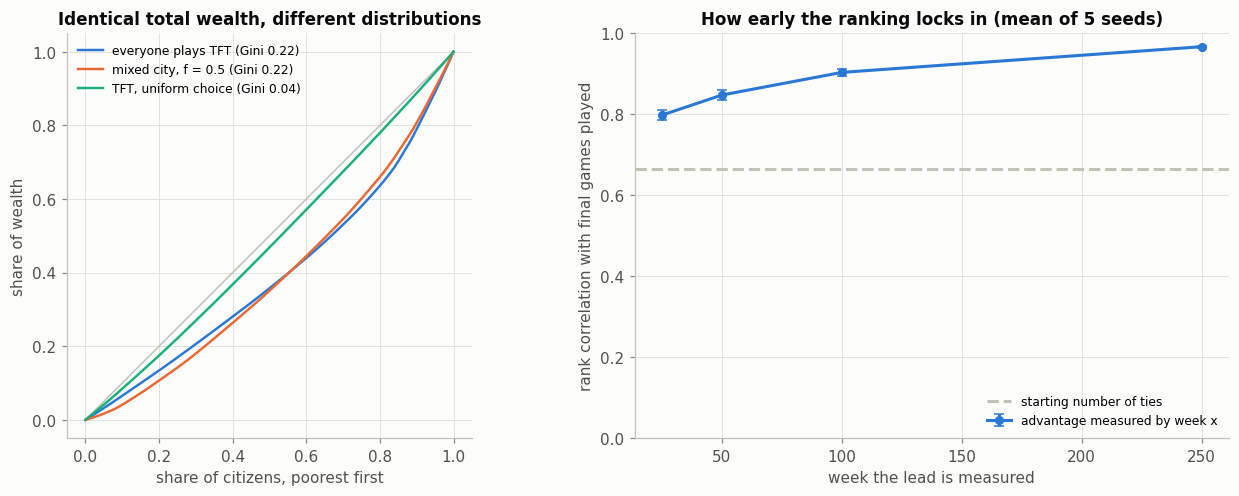

every move cooperative, so wealth is exactly three times games played: True
lock-in, mean of 5 seeds (se in brackets): week 25 0.80 (0.01), week 50 0.85 (0.01), week 100 0.90 (0.01), week 250 0.97 (0.00) | starting ties 0.66 (0.03)
TFT-only Gini 0.210 | mixed city Gini 0.226 (se 0.011, 5 seeds each)


,scenario,gini,mean_wealth,gini_se,mean_wealth_se
0,full: habit x status,0.2104,3000.0,0.0041,0.0
1,habit only,0.0524,3000.0,0.0005,0.0
2,neither: uniform,0.0494,3000.0,0.0038,0.0
3,status only,0.1324,3000.0,0.0039,0.0


In [14]:
CHOICE_VARIANTS = {
    "full: habit x status": ("M4", {}),
    "status only":          ("M4", {"encounter.weight_exponent": 0.0}),
    "habit only":           ("M4", {"encounter.popularity_exponent": 0.0}),
    "neither: uniform":     ("M4", {"encounter.weight_exponent": 0.0, "encounter.popularity_exponent": 0.0}),
}
ALL_TFT = {"population.giver_composition": {"tft": 1.0}}
tft_runs = R.sweep(CHOICE_VARIANTS, [1.0], n_seeds=N_SEEDS, workers=WORKERS, **{**SETTINGS, **ALL_TFT})
decomposition = R.cell_means(tft_runs, ["gini", "mean_wealth"], by=("scenario",))

# The mixed city on the same seeds, so the two Ginis compared in the text are the same kind of
# number: a mean over runs, not one city against an average.
mixed_reference = R.sweep({"mixed city, f = 0.5": ("M4", {})}, [0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)

curves, curve_ginis = {}, {}
for label, overrides in [("everyone plays TFT", {**ALL_TFT, "population.giver_fraction": 1.0}),
                         ("mixed city, f = 0.5", {"population.giver_fraction": 0.5}),
                         ("TFT, uniform choice", {**ALL_TFT, "population.giver_fraction": 1.0,
                                                  "encounter.weight_exponent": 0.0,
                                                  "encounter.popularity_exponent": 0.0})]:
    sim = Simulation(stage("M4", **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED,
                     repeat=0, instruments=("core",))
    sim.run()
    curves[label], curve_ginis[label] = metrics.lorenz(sim.state.wealth), metrics.gini(sim.state.wealth)

# Does an early lead survive? Rank citizens by games played at several points, against the end.
# Averaged over the same seeds as everything else, rather than read off one city.
MARKS = [25, 50, 100, 250]
lock_rows = []
for repeat in range(N_SEEDS):
    watch = Simulation(stage("M4", **{**SETTINGS, **ALL_TFT, "population.giver_fraction": 1.0}),
                       root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    marks = {}
    for _ in range(SETTINGS["run.n_rounds"]):
        watch.run_round()
        if watch.state.t in MARKS:
            marks[watch.state.t] = watch.state.games_played.copy()
    final_games = watch.state.games_played
    lock_rows.append({**{week: metrics.spearman(marks[week], final_games) for week in MARKS},
                      "starting ties": metrics.spearman(watch.state.capacity, final_games),
                      "wealth is exactly 3x games": np.allclose(watch.state.wealth, 3.0 * final_games)})
lock = pd.DataFrame(lock_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
P.lorenz_curves(axes[0], curves, ginis=curve_ginis)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Identical total wealth, different distributions")
axes[1].errorbar(MARKS, lock[MARKS].mean(), yerr=lock[MARKS].sem(), color=P.SERIES[0],
                 marker="o", capsize=3, label="advantage measured by week x")
axes[1].axhline(lock["starting ties"].mean(), color=P.AXIS, linestyle="--",
                label="starting number of ties")
axes[1].set(xlabel="week the lead is measured", ylabel="rank correlation with final games played",
            ylim=(0, 1), title=f"How early the ranking locks in (mean of {N_SEEDS} seeds)")
axes[1].legend(fontsize=8, loc="lower right")
P.save(fig, "positional")
plt.show()

print(f"every move cooperative, so wealth is exactly three times games played: "
      f"{lock['wealth is exactly 3x games'].all()}")
print(f"lock-in, mean of {N_SEEDS} seeds (se in brackets): "
      + ", ".join(f"week {w} {lock[w].mean():.2f} ({lock[w].sem():.2f})" for w in MARKS)
      + f" | starting ties {lock['starting ties'].mean():.2f} ({lock['starting ties'].sem():.2f})")
print(f"TFT-only Gini {decomposition.set_index('scenario').loc['full: habit x status', 'gini']:.3f} "
      f"| mixed city Gini {mixed_reference['gini'].mean():.3f} "
      f"(se {mixed_reference['gini'].sem():.3f}, {N_SEEDS} seeds each)")
decomposition.round(4)

**What this shows:**

| Partner choice, everyone plays TFT | Gini | Wealth per person |
|---|---|---|
| Full: habit x status | 0.210 | 3,000 |
| Status only | 0.132 | 3,000 |
| Habit only | 0.052 | 3,000 |
| Neither: uniform | 0.049 | 3,000 |

**Wealth per person is identical to the unit in all four:** The *city* plays the same number of
games in total whatever the choice rule is, and every game pays 3 to each side, so the total
wealth is fixed by the rules before anyone meets anyone. What varies is who those games go to,
and that alone moves the Gini from 0.049 to 0.210, a factor of four.

**Status is the whole of it:** Removing status returns inequality to the uniform baseline
(0.052 against 0.049, a difference smaller than either standard error); removing habit leaves
most of it standing (0.132, or +0.083 over baseline). Habit on its own contributes nothing
measurable. Yet the two together produce +0.161 over baseline, about twice what status manages
alone, so they compound rather than add: the rating is a product of cooperativeness and *relative
tie strength*, and habit builds the strength that status then rewards. Habit is not a channel to
inequality by itself; it is the raw material status works on.

**And the ranking locks in early:** Averaged over the same seeds, the rank correlation between
games played by week 25 and games played at week 500 is +0.80, rising to +0.97 by week 250. A
citizen's starting number of ties predicts the final count at +0.66 on its own. So the answer to
the original question is: yes, some citizens do get into positively reinforced relationships
early, and the advantage is close to permanent by the time the city is a tenth of the way through
its life. No exploitation is required, and none occurs.

This is the sharpest statement of the project's central conclusion without refusal. A TFT-only
city reaches a Gini of 0.210 and a mixed city 0.226, both means over the same seeds: nearly the
same inequality from completely different moral material. **Inequality here is positional, not
extractive.** The Lorenz curve of a city where nobody can be cheated looks like the Lorenz curve of
one where half the population cheats, because in both the binding constraint is who gets met.

> **Insight 6, inequality without refusal is positional:** a city where nobody is ever cheated is nearly as unequal as a mixed one, because status steers attention to the already popular and early luck becomes a lasting rank.
>
> **Real life or model?** Both. Cumulative advantage is real: in an online music market with 14,341 participants, letting people see what others chose made success both more unequal and less predictable, and quality decided it only in part [[15]]. But the size of the effect here is ours: the rating multiplies cooperation by relative tie strength, which builds a rich-get-richer step into the model, and removing the status term removes the inequality.

### The Right to Refuse

S6 adds one rule to the full city: once a partner has defected on you, you stop meeting them and the tie between you ends (rule 4 above). It is the "Walk Away" rule, which in evolutionary simulations lets cooperators invade a population of defectors more easily than any other strategy tested [16]. Here it is a norm every citizen follows, givers and takers alike, so nobody is told to avoid takers. The figure compares the same cities with and without it.

**The figure:** four panels against the giver fraction, comparing the same cities without refusal (S5, dashed) and with it (S6, solid). From left: wealth per giver (blue) and per taker (orange); wealth per person for the whole city; the Gini of wealth; and the share of takers holding no ties at week 500.

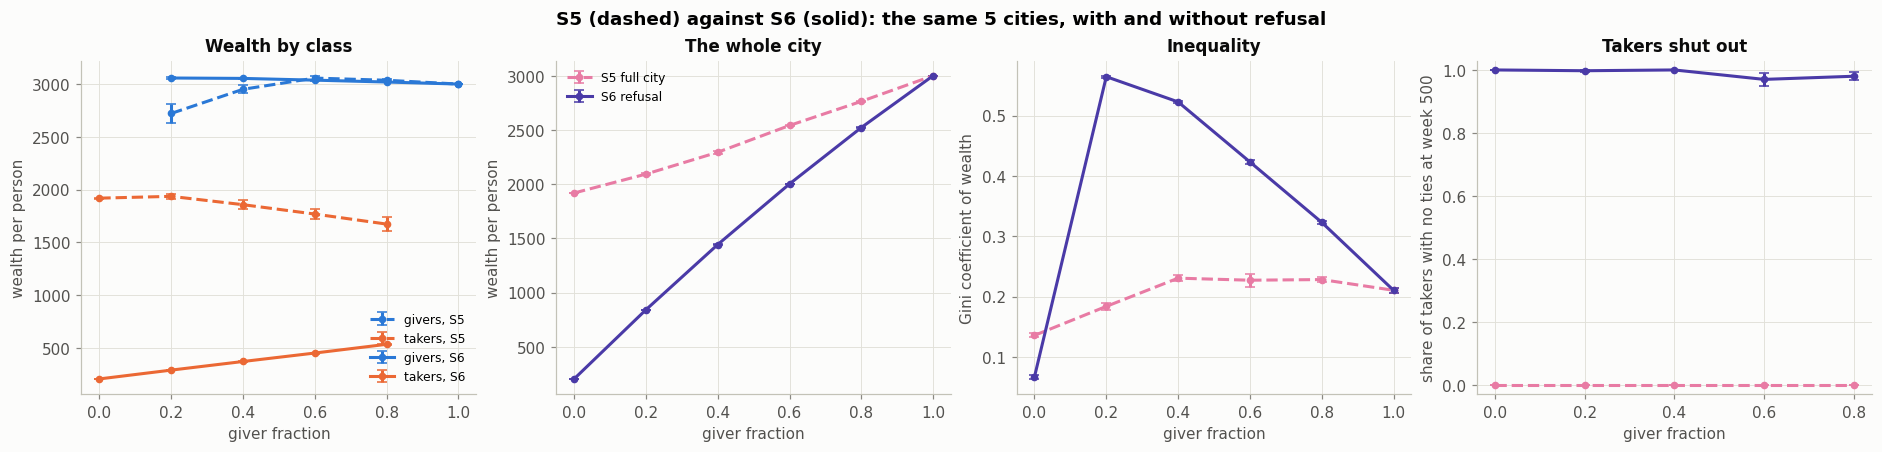

gini             mean_wealth             \
scenario       S5 full city S6 refusal S5 full city S6 refusal   
giver_fraction                                                   
0.0                   0.136      0.067     1918.346    204.772   
0.2                   0.184      0.564     2092.656    842.060   
0.4                   0.230      0.523     2294.066   1443.368   
0.6                   0.227      0.423     2540.986   2002.224   
0.8                   0.228      0.323     2763.264   2521.914   
1.0                   0.210      0.210     3000.000   3000.000   

               taker_games_per_week            takers_cut_off             \
scenario               S5 full city S6 refusal   S5 full city S6 refusal   
giver_fraction                                                             
0.0                           2.000      0.234            0.0      1.000   
0.2                           1.760      0.243            0.0      0.997   
0.4                           1.509      0.252            0.0      1.000   
0.6                           1.326      0.261            0.0      0.970   
0.8                           1.256      0.272            0.0      0.980   
1.0                             NaN        NaN            NaN        NaN   

               wealth_giver            wealth_taker             
scenario       S5 full city S6 refusal S5 full city S6 refusal  
giver_fraction                                                  
0.0                     NaN        NaN     1918.346    204.772  
0.2                2721.430   3057.330     1935.462    288.242  
0.4                2950.365   3053.540     1856.533    369.920  
0.6                3056.590   3036.983     1767.580    450.085  
0.8                3035.950   3019.170     1672.520    532.890  
1.0                3000.000   3000.000          NaN        NaN

In [15]:
pair = runs[runs["scenario"].isin(["S5 full city", "S6 refusal"])].copy()
takers = (1 - pair["giver_fraction"]) * SETTINGS["population.n_agents"]
pair["takers_cut_off"] = np.where(takers > 0, pair["isolated_taker"] / takers.where(takers > 0, 1), np.nan)
pair["taker_games_per_week"] = pair["games_taker"] / SETTINGS["run.n_rounds"]
refuse = R.cell_means(pair, ["wealth_giver", "wealth_taker", "mean_wealth", "gini", "takers_cut_off",
                             "taker_games_per_week"])
STYLE = {"S5 full city": "--", "S6 refusal": "-"}

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for name in ["S5 full city", "S6 refusal"]:
    rows = refuse[refuse["scenario"] == name]
    for cls in ("giver", "taker"):
        axes[0].errorbar(rows["giver_fraction"], rows[f"wealth_{cls}"], yerr=rows[f"wealth_{cls}_se"],
                         color=P.CLASS_COLOURS[cls], linestyle=STYLE[name], marker="o", markersize=4,
                         capsize=3, label=f"{cls}s, {name.split()[0]}")
    for ax, metric in zip(axes[1:], ["mean_wealth", "gini", "takers_cut_off"]):
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"], color=colours[name],
                    linestyle=STYLE[name], marker="o", markersize=4, capsize=3, label=name)
axes[0].set(xlabel="giver fraction", ylabel="wealth per person", title="Wealth by class")
axes[1].set(xlabel="giver fraction", ylabel="wealth per person", title="The whole city")
axes[2].set(xlabel="giver fraction", ylabel="Gini coefficient of wealth", title="Inequality")
axes[3].set(xlabel="giver fraction", ylabel="share of takers with no ties at week 500",
            title="Takers shut out", ylim=(-0.03, 1.03))
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle(f"S5 (dashed) against S6 (solid): the same {N_SEEDS} cities, with and without refusal",
             fontweight="bold")
P.save(fig, "refusal")
plt.show()

refuse.pivot_table(index="giver_fraction", columns="scenario",
                   values=["wealth_giver", "wealth_taker", "mean_wealth", "gini", "takers_cut_off",
                           "taker_games_per_week"]).round(3)

**What this shows:**

- **Givers are protected:** Under refusal a giver ends with about 3,000 at every mix (3,057 at `f = 0.2`, against 2,721 without refusal). Under refusal, a giver's fortune does not depend on how many takers live in the city.
- **Takers are shut out, not sorted:** In mixed cities, between 97% and 100% of takers hold no ties at all by week 500. A taker plays about a quarter of a game a week (0.24 to 0.27), against 1.3 to 1.8 without refusal, and ends with 290 to 530 instead of 1,670 to 1,940.
- **The city gets poorer where takers are common:** Wealth per person at `f = 0.2` falls from 2,093 to 842; at `f = 0.8` it falls only from 2,763 to 2,522. A citizen nobody will meet produces nothing, for anyone, and a taker still created some wealth even while it was exploiting someone.
- **Inequality changes shape:** The Gini peaks at 0.564 in taker-dominated cities and falls to 0.323 at `f = 0.8`, against a flat 0.18 to 0.23 without refusal. This is why H4 is refuted on S6: the few givers in a taker city stay rich while everyone around them is shut out.
- **Takers form no cliques of their own:** A taker defects on other takers too, so a pair of takers closes as fast as a taker and a giver. Shut-out takers end as isolated citizens, not as a second community, which is visible in the animation further down.

> **Insight 7, refusal turns exploitation into exclusion:** givers are protected, takers end with no ties, and taker-heavy cities become poorer and far more unequal.
>
> **Real life or model?** The protection is real: people do cut ties with defectors [[17]], and in experiments ostracising selfish players lets groups cooperate with less exploitation [[18]]. The cost is partly the model. In those experiments ostracised players responded by cooperating as much as everyone else [[18]]; our takers can never change, so exclusion is permanent, and since wealth is created only by meeting, an excluded citizen produces nothing at all. Real exclusion is likely cheaper and less final than it is here.

In [16]:
# Does a giver who starts surrounded by takers stay poorer? Each giver's share of giver
# neighbours at week 0, against that giver's wealth at week 500, in cities where givers are scarce.
def start_and_finish(task):
    base, repeat = task
    sim = Simulation(stage(base, **{**SETTINGS, "population.giver_fraction": 0.2}),
                     root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    start, giver = sim.state.adjacency.copy(), sim.state.giver
    share = (start & giver[None, :]).sum(axis=1) / np.maximum(start.sum(axis=1), 1)
    sim.run()
    w = sim.state.wealth
    alone = giver & (share == 0)
    return {"scenario": {"M4": "S5 full city", "M5": "S6 refusal"}[base], "repeat": repeat,
            "rank correlation, start vs final wealth": metrics.spearman(share[giver], w[giver]),
            "givers with no giver neighbours": int(alone.sum()),
            "their wealth": w[alone].mean() if alone.any() else np.nan,
            "all givers' wealth": w[giver].mean()}


surround = pd.DataFrame(R.parallel_map(start_and_finish, [(b, r) for b in ("M4", "M5") for r in range(N_SEEDS)],
                                     workers=WORKERS))
surround["their shortfall"] = 1 - surround["their wealth"] / surround["all givers' wealth"]
summary = surround.groupby("scenario").agg(["mean", "sem"]).drop(columns="repeat")
summary.round(3)

rank correlation, start vs final wealth         \
                                                mean    sem   
scenario                                                      
S5 full city                                   0.363  0.062   
S6 refusal                                     0.235  0.077   

             givers with no giver neighbours        their wealth           \
                                        mean    sem         mean      sem   
scenario                                                                    
S5 full city                             4.8  1.068     1834.425  167.603   
S6 refusal                               4.8  1.068     2544.803  233.847   

             all givers' wealth         their shortfall         
                           mean     sem            mean    sem  
scenario                                                        
S5 full city            2721.43  87.389           0.317  0.080  
S6 refusal              3057.33   6.989           0.168  0.075

**A giver surrounded by takers:** in cities where givers are scarce (`f = 0.2`), about 5 givers per city start with no giver neighbours at all. Without refusal they end 32% poorer than the average giver (1,834 against 2,721), and the share of givers among a giver's starting neighbours predicts its final wealth (rank correlation 0.36). Under refusal the shortfall is smaller (17%, correlation 0.24), but at 5 seeds the two shortfalls overlap within their standard errors (0.08 and 0.08). Walking away frees such a giver from the takers around it; it does not shorten the distance to other givers, which partner choice only reaches up to three handshakes away.

> **Insight 8, where a giver starts still matters:** a giver whose first neighbours are all takers ends poorer, with or without refusal.
>
> **Real life or model?** Consistent with real neighbourhood effects on mobility [2], but small and noisy here: at 5 seeds the difference between S5 and S6 is within its standard errors.

### How Long to Hold a Grudge

S6 never forgives. Here a closed pair reopens `W` weeks after its last game, so the dial runs from never refusing (S5) to never forgiving (S6), in cities with 20% and 50% givers. The `idle` column in the table is the number of citizens per week, averaged over the last 100 weeks, who had nobody within reach willing to meet them.

**The figure:** the horizontal axis is how many weeks a pair stays closed after a defection, from never (S5) through 1 to 208 weeks to forever (S6); the steps are not evenly spaced. Light lines are cities with 20% givers and dark lines 50%. From left: the Gini of wealth; the share of inequality lying between givers and takers (0 none, 1 all); wealth per giver (blue) and per taker (orange); and wealth per person.

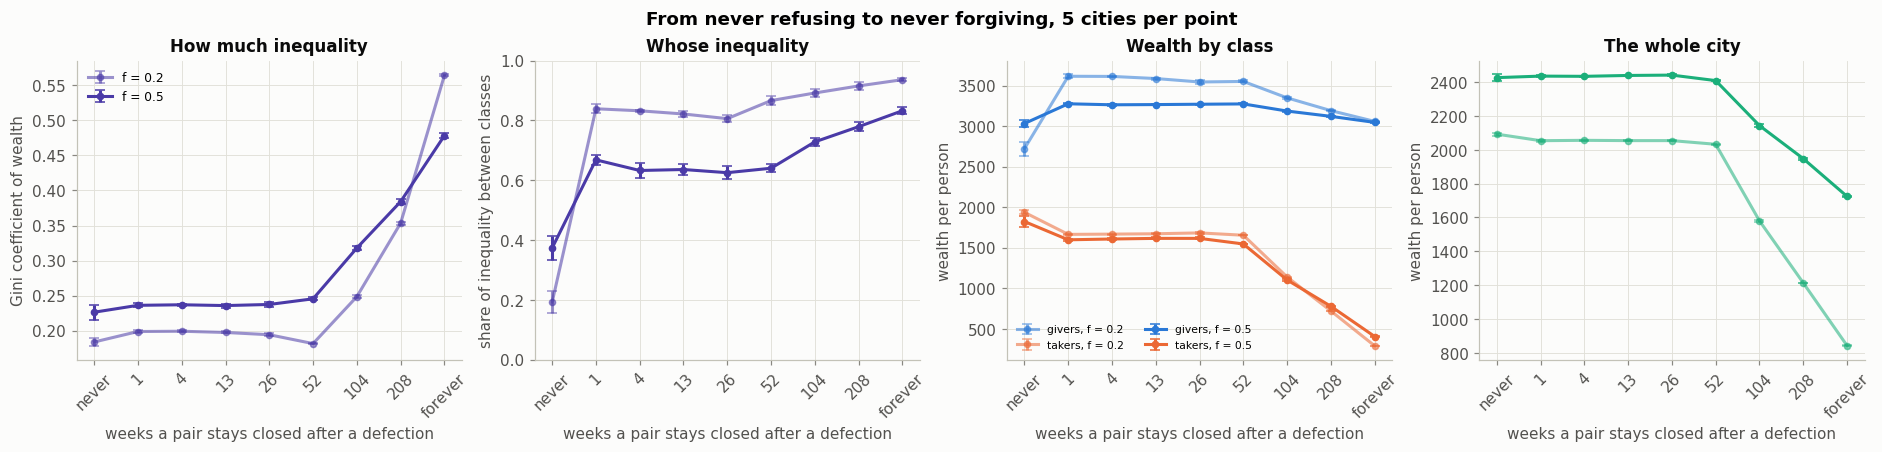

gini        between_share        wealth_giver            \
giver_fraction    0.2    0.5           0.2    0.5          0.2       0.5   
scenario                                                                   
never           0.184  0.226         0.192  0.373      2721.43  3031.408   
1               0.199  0.236         0.839  0.668      3614.14  3274.712   
4               0.199  0.237         0.832  0.632      3612.22  3262.196   
13              0.197  0.236         0.821  0.636      3585.99  3264.884   
26              0.194  0.237         0.806  0.625      3543.55  3269.132   
52              0.181  0.245         0.866  0.640      3550.29  3272.980   
104             0.248  0.318         0.891  0.728      3347.46  3184.932   
208             0.353  0.384         0.915  0.779      3190.24  3119.484   
forever         0.564  0.478         0.936  0.832      3057.33  3045.084   

               wealth_taker           mean_wealth              idle          
giver_fraction          0.2       0.5         0.2       0.5     0.2     0.5  
scenario                                                                     
never              1935.462  1822.108    2092.656  2426.758   0.000   0.000  
1                  1663.805  1596.880    2053.872  2435.796   0.002   0.000  
4                  1666.985  1606.772    2056.032  2434.484   0.004   0.000  
13                 1671.367  1614.428    2054.292  2439.656   0.004   0.006  
26                 1682.048  1614.372    2054.348  2441.752   0.004   0.004  
52                 1653.222  1545.548    2032.636  2409.264   0.990   2.464  
104                1137.908  1101.300    1579.818  2143.116  27.114  17.908  
208                 718.645   776.064    1212.964  1947.774  30.048  22.930  
forever             288.242   403.912     842.060  1724.498  79.674  49.442

In [17]:
# A pair that has had a defection stays closed for this many weeks after their last game.
MEMORY = [1, 4, 13, 26, 52, 104, 208]
GRUDGE = {"never": ("M4", {}),
          **{str(w): ("M5", {"encounter.refusal_memory": w}) for w in MEMORY},
          "forever": ("M5", {})}
grudge = R.sweep(GRUDGE, [0.2, 0.5], n_seeds=N_SEEDS, workers=WORKERS, **SETTINGS)
grudge["between_share"] = grudge["theil_between"] / grudge["theil"]
dial_means = R.cell_means(grudge, ["gini", "between_share", "wealth_giver", "wealth_taker", "mean_wealth", "idle"])
order = list(GRUDGE)
dial_means["position"] = dial_means["scenario"].map({name: k for k, name in enumerate(order)})

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
shade = {0.2: 0.55, 0.5: 1.0}
for f in (0.2, 0.5):
    rows = dial_means[np.isclose(dial_means["giver_fraction"], f)].sort_values("position")
    x = rows["position"]
    for ax, metric, colour in [(axes[0], "gini", P.SERIES[6]), (axes[1], "between_share", P.SERIES[6]),
                               (axes[3], "mean_wealth", P.SERIES[2])]:
        ax.errorbar(x, rows[metric], yerr=rows[f"{metric}_se"], color=colour, alpha=shade[f],
                    marker="o", markersize=4, capsize=3, label=f"f = {f}")
    for cls in ("giver", "taker"):
        axes[2].errorbar(x, rows[f"wealth_{cls}"], yerr=rows[f"wealth_{cls}_se"], color=P.CLASS_COLOURS[cls],
                         alpha=shade[f], marker="o", markersize=4, capsize=3, label=f"{cls}s, f = {f}")
for ax, label, title in [(axes[0], "Gini coefficient of wealth", "How much inequality"),
                         (axes[1], "share of inequality between classes", "Whose inequality"),
                         (axes[2], "wealth per person", "Wealth by class"),
                         (axes[3], "wealth per person", "The whole city")]:
    ax.set_xticks(range(len(order)), order, rotation=45)
    ax.set(xlabel="weeks a pair stays closed after a defection", ylabel=label, title=title)
axes[1].set_ylim(0, 1)
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=7, ncol=2)
fig.suptitle(f"From never refusing to never forgiving, {N_SEEDS} cities per point", fontweight="bold")
P.save(fig, "forgiveness")
plt.show()

dial_means.pivot_table(index="scenario", columns="giver_fraction",
                       values=["gini", "between_share", "wealth_giver", "wealth_taker", "mean_wealth", "idle"],
                       sort=False).loc[order].round(3)

**What this shows:**

- **A short grudge moves inequality without adding to it:** Refusing a defector for a single week barely changes the Gini (0.184 to 0.199 at `f = 0.2`) or wealth per person (2,093 to 2,054), but the share of inequality that lies between givers and takers jumps from 0.19 to 0.84. Givers gain (2,721 to 3,614) and takers lose (1,935 to 1,664). The amount of inequality stays about the same; who holds the bottom of it flips.
- **Nothing more changes until grudges last about a year:** From 1 to 52 weeks the four panels are flat.
- **Past a year, refusal starts to exclude, and exclusion costs the city:** At `f = 0.5`, wealth per person falls from 2,409 at 52 weeks to 2,143 at 104, 1,948 at 208 and 1,724 when nobody forgives, and the Gini rises from 0.245 to 0.478. The `idle` column shows why: at 26 weeks almost nobody is ever left without a willing partner, at 52 weeks about 2 citizens a week are, and at 104 weeks about 18 are. The city loses wealth exactly when takers start running out of people who will still meet them.

So the right to refuse does two different things depending on how long it lasts. A short memory protects givers at almost no cost to the city. A long one punishes takers by excluding them, and the city pays for that exclusion with the output the takers would otherwise have produced.

> **Insight 9, a short grudge changes who is poor, a long one shrinks the city:** refusing for up to about a year moves inequality onto the takers at almost no cost; refusing for longer excludes them, once they run out of anyone willing to meet them.
>
> **Real life or model?** The direction is plausible, since forgiveness lets an exploiter keep finding partners. The one-year turning point is not a real duration: it depends on a city of 100, a reach of three handshakes and one meeting a week, and would move with any of them.

### What the Gini Cannot See

The Gini of wealth sits between about 0.16 and 0.25 in almost every networked city without refusal, whatever the mix and whether or not anyone is exploited. Two questions follow: where does that number come from, and whose inequality is it? The left panel plots each city's Gini of wealth against its Gini of games played. The right panel splits inequality with the Theil index, which, unlike the Gini, adds up exactly into a part within each class and a part between the classes [19].

**The figure:** left, one dot per city, coloured by scenario: the Gini of games played (horizontal) against the Gini of wealth (vertical). On the diagonal, wealth is exactly as unequal as attention; above it, what each game pays adds inequality; below it, it removes some. Centre: the Gini of wealth against the giver fraction for four scenarios. Right: the share of that inequality lying between givers and takers, from the Theil index.

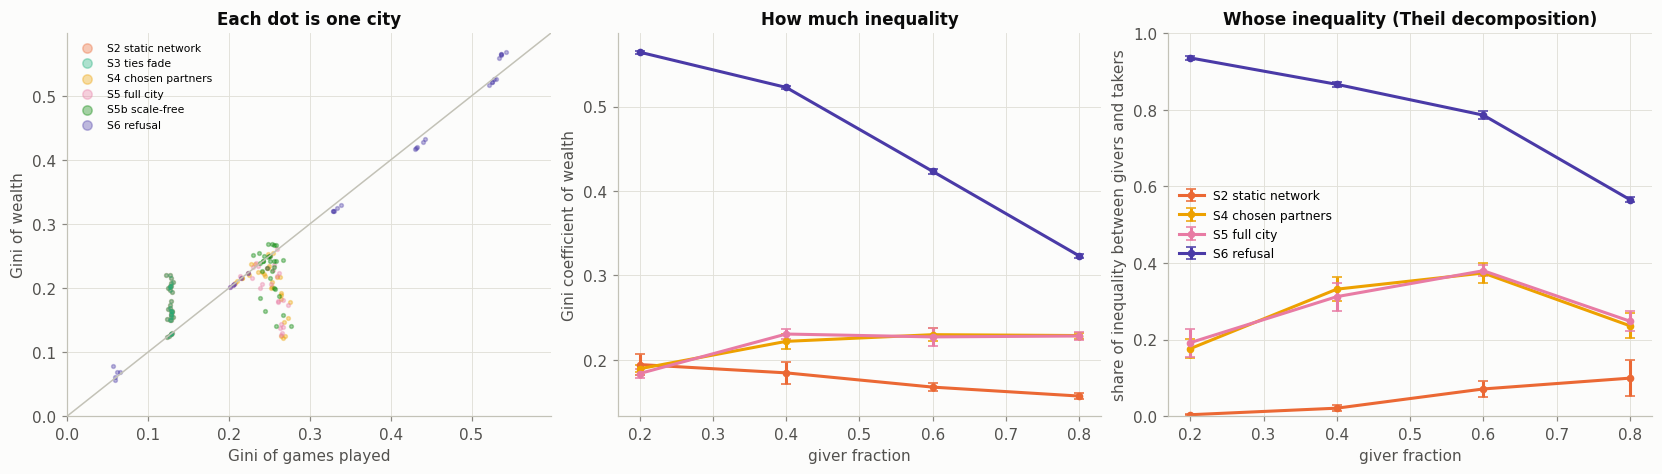

rank correlation of Gini of wealth with Gini of games played, networked cities: 0.52 (180 cities)


between_share                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.2                    0.102             0.004        0.004   
0.4                    0.008             0.021        0.021   
0.6                    0.245             0.071        0.071   
0.8                    0.634             0.099        0.099   

                                                                          \
scenario       S4 chosen partners S5 full city S5b scale-free S6 refusal   
giver_fraction                                                             
0.2                         0.176        0.192          0.102      0.936   
0.4                         0.332        0.312          0.187      0.867   
0.6                         0.374        0.380          0.318      0.786   
0.8                         0.236        0.248          0.220      0.566   

                        gini                                 ...               \
scenario       S1 well-mixed S2 static network S3 ties fade  ... S5 full city   
giver_fraction                                               ...                
0.2                    0.081             0.194        0.194  ...        0.184   
0.4                    0.050             0.184        0.184  ...        0.230   
0.6                    0.036             0.168        0.168  ...        0.227   
0.8                    0.031             0.157        0.157  ...        0.228   

                                          gini_surplus                    \
scenario       S5b scale-free S6 refusal S1 well-mixed S2 static network   
giver_fraction                                                             
0.2                     0.213      0.564         0.175             0.364   
0.4                     0.241      0.523         0.095             0.304   
0.6                     0.248      0.423         0.061             0.243   
0.8                     0.251      0.323         0.046             0.197   

                                                                            \
scenario       S3 ties fade S4 chosen partners S5 full city S5b scale-free   
giver_fraction                                                               
0.2                   0.364              0.254        0.248          0.299   
0.4                   0.304              0.264        0.271          0.291   
0.6                   0.243              0.243        0.236          0.264   
0.8                   0.197              0.234        0.235          0.256   

                           
scenario       S6 refusal  
giver_fraction             
0.2                 0.586  
0.4                 0.521  
0.6                 0.417  
0.8                 0.318  

[4 rows x 21 columns]

In [18]:
# With every payoff between S = 0 and T = 5, wealth is roughly (payoff per game) x (games played),
# so the Gini of wealth should track the Gini of games played.
networked = runs[runs["scenario"] != "S1 well-mixed"]
mixed_runs = runs[runs["giver_fraction"].between(0.15, 0.85)].assign(
    between_share=lambda d: d["theil_between"] / d["theil"])
split = R.cell_means(mixed_runs, ["gini", "between_share", "gini_surplus"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name in [s for s in SCENARIOS if s != "S1 well-mixed"]:
    rows = networked[networked["scenario"] == name]
    axes[0].scatter(rows["gini_games"], rows["gini"], s=6, alpha=0.35, color=colours[name], label=name)
top = max(networked["gini"].max(), networked["gini_games"].max()) * 1.05
axes[0].plot([0, top], [0, top], color=P.AXIS, linewidth=1)
axes[0].set(xlabel="Gini of games played", ylabel="Gini of wealth", xlim=(0, top), ylim=(0, top),
            title="Each dot is one city")
axes[0].legend(fontsize=7, markerscale=2.5, loc="upper left")
for name in ["S2 static network", "S4 chosen partners", "S5 full city", "S6 refusal"]:
    rows = split[split["scenario"] == name]
    for ax, metric in zip(axes[1:], ["gini", "between_share"]):
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"], color=colours[name],
                    marker="o", markersize=4, capsize=3, label=name)
axes[1].set(xlabel="giver fraction", ylabel="Gini coefficient of wealth", title="How much inequality")
axes[2].set(xlabel="giver fraction", ylabel="share of inequality between givers and takers",
            ylim=(0, 1), title="Whose inequality (Theil decomposition)")
axes[2].legend(fontsize=8)
P.save(fig, "gini_decomposition")
plt.show()

print(f"rank correlation of Gini of wealth with Gini of games played, networked cities: "
      f"{metrics.spearman(networked['gini'], networked['gini_games']):.2f} ({len(networked)} cities)")
split.pivot_table(index="giver_fraction", columns="scenario",
                  values=["gini", "gini_surplus", "between_share"]).round(3)

**What this shows:**

- **The Gini mostly measures attention, with a twist:** Across 180 networked cities, the Gini of wealth and the Gini of games played are rank-correlated at 0.52. The cities fall into three groups. In S2 and S3, where partners are drawn uniformly, everyone plays a similar number of games and the dots sit *above* the diagonal: the inequality comes from what each game pays. In S4 and S5 attention is unequal, but the dots sit on or *below* the diagonal, because the takers who are met least earn the most per game, so exploitation partly cancels the inequality of attention. In S6 the dots sit exactly on the diagonal: a taker who is shut out neither plays nor earns.
- **Similar Ginis hide different cities:** In S2 almost none of the inequality lies between the classes (0.004 to 0.099). In S5 a fifth to two fifths does (0.19 to 0.38). Under refusal most of it does (0.57 to 0.94). A Gini near 0.2 can describe a city where luck of position decides who is poor, or one where class does.
- **Charging every game its mutual-defection payoff changes the yardstick, not the city:** Subtracting `P = 1` per game, so that being exploited costs wealth (payoffs 4, 2, 0, -1), raises the Gini most where givers cannot avoid takers: in S2 and S3 at `f = 0.2` it nearly doubles (0.194 to 0.364) and moves above S5 (0.248), while under refusal, where the games that remain are almost all cooperative, it barely moves (0.564 to 0.586, and slightly down at `f >= 0.6`). No citizen's choices ever depend on its wealth, so this rescaling cannot change anything that happens; it changes how the outcome is scored, and it makes exploitation visible where the plain Gini hides it.

> **Insight 10, the Gini cannot say who is poor:** cities with nearly the same Gini can have their inequality almost entirely within classes or almost entirely between them.
>
> **Real life or model?** This is a property of the measure, not of the model, and it holds for any population: the Gini is one number for a whole distribution, while the Theil index splits exactly into within-group and between-group parts [[19]].

### A Taker That Looks Like a Giver

AllD and Random are easy to read: one never cooperates and the other cooperates at a coin toss. Joss, named after an entry in Axelrod's first tournament [20], plays Tit-for-Tat but slips in an unprovoked defection one game in ten, so most of its record is cooperative. Here the taker class is split equally between AllD, Random and Joss, at `f = 0.5`, with and without refusal.

**The figure:** one pair of bars per strategy, with givers left of the vertical line and takers right of it; hatched bars are S5 and plain bars S6, in cities with 50% givers and the takers split equally between AllD, Random and Joss. From left: wealth at week 500; popularity rating at week 500, which is all other citizens can see; and the share of each strategy holding no ties at week 500.

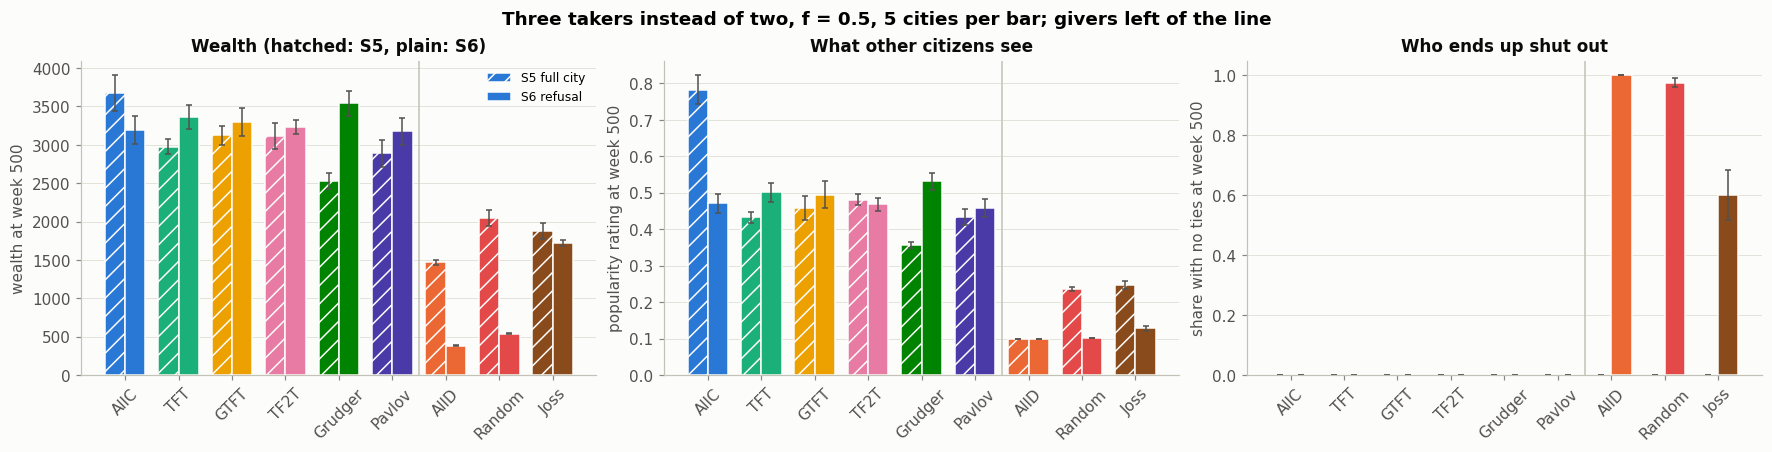

,S5 full city,S6 refusal
wealth AllD,1466.941,382.553
wealth Random,2049.294,537.824
wealth Joss,1876.050,1719.562
games AllD,598.376,98.365
games Random,801.435,162.294
games Joss,834.450,578.225
rating AllD,0.100,0.100
rating Random,0.235,0.100
rating Joss,0.247,0.128
isolated AllD,0.000,1.000


In [19]:
# A third kind of taker, mixed in equally with AllD and Random, at f = 0.5.
THREE_TAKERS = {"population.taker_composition": {"alld": 1.0, "random": 1.0, "joss": 1.0}}
JOSS_SCENARIOS = {"S5 full city": ("M4", THREE_TAKERS), "S6 refusal": ("M5", THREE_TAKERS)}
joss = R.sweep(JOSS_SCENARIOS, [0.5], n_seeds=N_SEEDS, instruments=("core", "snapshot"),
                workers=WORKERS, **SETTINGS)
KEYS = ["allc", "tft", "gtft", "tf2t", "grudger", "pavlov", "alld", "random", "joss"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
width = 0.38
x = np.arange(len(KEYS))
for k, (name, hatch) in enumerate([("S5 full city", "//"), ("S6 refusal", None)]):
    rows = joss[joss["scenario"] == name]
    for ax, measure in zip(axes, ["wealth", "rating", "isolated"]):
        values = [rows[f"{measure}_{key}"].mean() for key in KEYS]
        errors = [rows[f"{measure}_{key}"].sem() for key in KEYS]
        ax.bar(x + (k - 0.5) * width, values, width, yerr=errors, capsize=2, hatch=hatch,
               color=[P.STRATEGY_COLOURS[key] for key in KEYS], edgecolor=P.SURFACE, label=name,
               error_kw={"ecolor": P.INK_2, "elinewidth": 1})
for ax, label in zip(axes, ["wealth at week 500", "popularity rating at week 500",
                            "share with no ties at week 500"]):
    ax.set_xticks(x, [P.STRATEGY_LABELS[key] for key in KEYS], rotation=45)
    ax.set_ylabel(label)
    ax.axvline(5.5, color=P.AXIS, linewidth=1)
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8, loc="upper right")
axes[0].set_title("Wealth (hatched: S5, plain: S6)")
axes[1].set_title("What other citizens see")
axes[2].set_title("Who ends up shut out")
fig.suptitle(f"Three takers instead of two, f = 0.5, {N_SEEDS} cities per bar; givers left of the line",
             fontweight="bold")
P.save(fig, "joss")
plt.show()

pd.DataFrame({name: {f"{measure} {P.STRATEGY_LABELS[key]}": joss[joss["scenario"] == name][f"{measure}_{key}"].mean()
                     for measure in ["wealth", "games", "rating", "isolated"] for key in ["alld", "random", "joss"]}
              for name in JOSS_SCENARIOS}).round(3)

**What this shows:**

- **Without refusal, Joss does no better than an honest coin toss:** Joss ends with 1,876, between AllD (1,467) and Random (2,049). Its occasional cheating sets off runs of mutual defection with retaliating givers, so its rating (0.25) is no better than Random's (0.24).
- **Refusal catches the obvious takers and misses the subtle one:** Under refusal AllD falls to 383 and Random to 538, a loss of about three quarters each, and almost all of them are shut out (100% and 98%). Joss falls only to 1,720, a loss of about a tenth: it plays 578 games against AllD's 98, and 40% of Joss players still hold ties at week 500. A citizen walks away only after being cheated, and Joss cooperates with each new partner for about ten games before it cheats.
- **The givers who gain most from refusal are the retaliators** (left panel). Grudger and Tit-for-Tat lose the most to takers when they cannot leave, because a defection locks them into mutual defection with that partner; walking away ends the loss instead. AllC is the one giver that does worse under refusal: without it, AllC is the most popular citizen (rating 0.78), partly because takers keep their ties to it, and those ties end once takers are shut out.

> **Insight 11, refusal by experience misses the rare cheat:** Joss loses about a tenth of its wealth to refusal, while AllD and Random lose about three quarters.
>
> **Real life or model?** Partly the model. Our citizens learn only from their own experience, so each must be cheated once before walking away. Real groups share reputations: gossip lets people avoid a defector they have never met [[18]], which would catch a Joss earlier. The model has this option (`encounter.refusal = "reputation"`) but it is not studied here.

### Watching a City Shut Its Takers Out

One 60-citizen city with half givers, followed for 300 weeks, with and without refusal. Both panels start from the same network and the same seed. Blue citizens are givers and orange are takers; node size is wealth and edge width is tie strength. A citizen with no ties is drawn on the outer ring, so leaving the city is visible as moving to the edge. The static frames are for print; the animation follows below them.

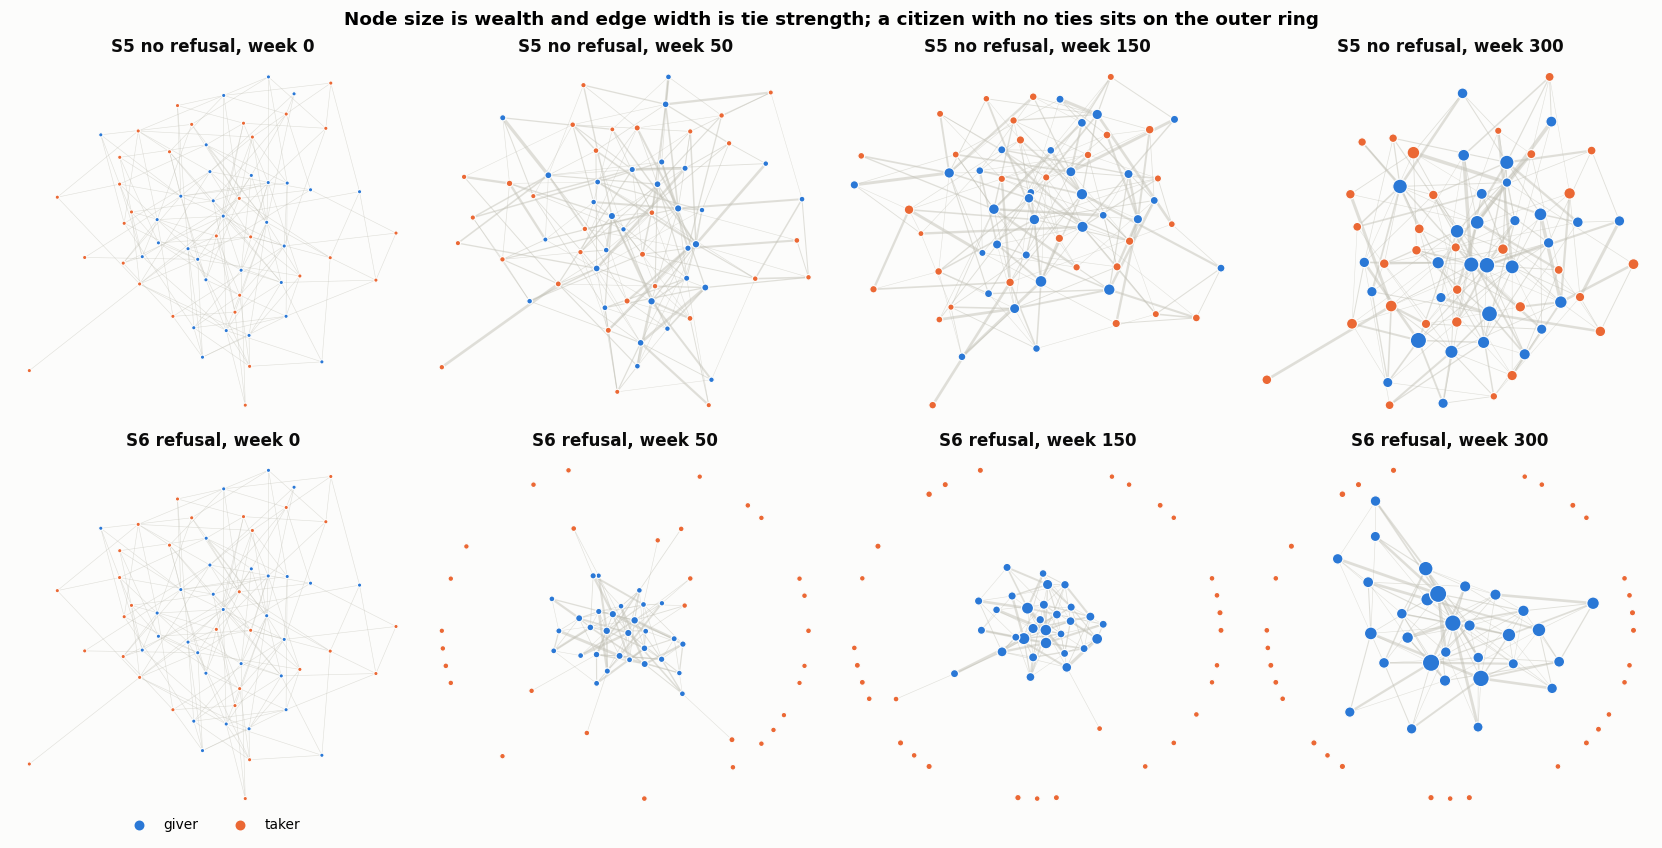

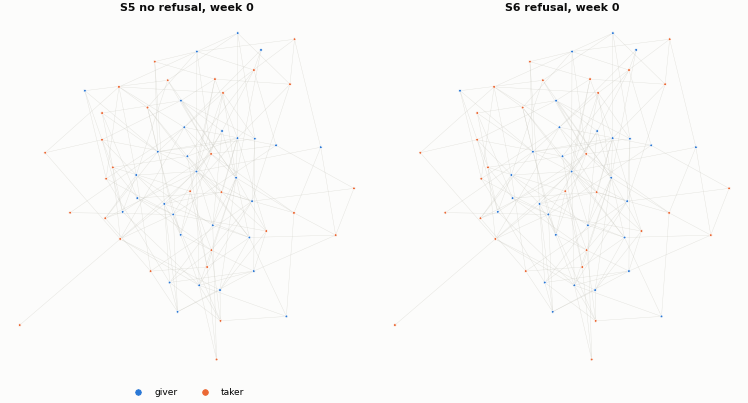

In [20]:
from IPython.display import Image
from utilities.network_draw import animate, class_legend, draw_snapshot, drifting_layouts

# One 60-citizen city at f = 0.5, the same seed and starting network with and without refusal,
# photographed every 10 weeks for 300 weeks.
FILM = {"population.n_agents": 60, "run.n_rounds": 300, "population.giver_fraction": 0.5,
        "metrics.snapshot_every": 10}
films = {label: Simulation(stage(base, **FILM), root_seed=R.DEFAULT_SEED, repeat=0,
                           instruments=("snapshots",)).run().outputs["snapshots"]
         for label, base in [("S5 no refusal", "M4"), ("S6 refusal", "M5")]}

shown = [0, 5, 15, 30]
wealth_scale = (0.0, max(f["wealth"].max() for frames in films.values() for f in frames))
weight_scale = max(f["weight"].max() for frames in films.values() for f in frames)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for row, (label, frames) in zip(axes, films.items()):
    positions = drifting_layouts(frames, seed=3)
    for ax, k in zip(row, shown):
        draw_snapshot(ax, frames[k], positions[k], title=f"{label}, week {frames[k]['round']}",
                      wealth_scale=wealth_scale, weight_scale=weight_scale, by_class=True)
class_legend(axes[1][0])
fig.suptitle("Node size is wealth and edge width is tie strength; a citizen with no ties sits on the "
             "outer ring", fontweight="bold")
P.save(fig, "city_refusal_frames")
plt.show()

(ROOT / "figures").mkdir(exist_ok=True)
Image(filename=str(animate(films, ROOT / "figures" / "city_refusal.gif", fps=2)))

**What to look for:** without refusal the two classes stay mixed through the whole run, and takers stay embedded among the givers, because they keep their ties to the givers they exploit. With refusal, takers leave one at a time from the first weeks: by week 50 many sit on the outer ring, and by week 150 nearly all do. The givers draw together into a dense core of thick ties. No group of takers forms on the ring, because takers walk away from each other too.

This is one small city and is not evidence on its own; the numbers in *The Right to Refuse* are.

> **Insight 12, shut-out takers form no community of their own:** they leave one at a time and never band together.
>
> **Real life or model?** The model. AllD and Random defect on everyone, other takers included, so two takers close their pair as fast as a taker and a giver. Real exploiters often cooperate with one another while exploiting outsiders, so a real city could well grow a second, taker community that this model cannot produce.

## Conclusions

- **More givers make a city richer, and without refusal the gain accelerates:** prosperity is set by how often givers meet each other, not by how many there are, so wealth per person bends upwards once givers pass about 30% of the city. Under refusal the bend disappears, because givers find each other however scarce they are.

- **Without refusal, prosperity and equality come apart:** inequality peaks in mixed cities rather than falling steadily as cooperation rises. On a scale-free network it stays high in the richest cities, because hubs capture the surplus. This runs against network-game results that report inequality falling with cooperation [4], and it does so through a mechanism those models do not have: who you can meet.

- **Inequality without refusal is positional, not extractive:** a city where every citizen plays Tit-for-Tat, and where no game is ever exploited, reaches a Gini of 0.210 against a mixed city's 0.226. Total wealth is identical however partners are chosen; only its distribution moves, and removing the status term from the choice rule collapses the Gini to 0.05. The rank order of who gets met is largely settled by week 25.

- **The right to refuse changes whose inequality it is, not how much:** a city whose citizens walk away from a defector for even one week has about the same Gini, but the share of inequality lying between givers and takers rises from about a fifth to more than four fifths. The Gini alone cannot tell these cities apart.

- **Refusal that never forgives becomes exclusion, and exclusion has a cost:** almost every taker ends with no ties, givers keep about 3,000 each at every mix, and taker-dominated cities become poor *and* unequal, which refutes H4 for this city. The city starts losing wealth once grudges outlast about a year, which is when takers begin to run out of anyone willing to meet them.

- **Refusal by experience is weakest against the subtle cheat:** it strips AllD and Random of about three quarters of their wealth, but Joss, which cooperates nine games in ten, keeps about nine tenths of its own.

- **Segregation emerges only with refusal:** without it, takers end with fewer partners and weaker ties, but the city becomes *disassortative*, because takers seek out givers who cannot refuse. With it, takers are shut out entirely, and they form no community of their own, because they walk away from each other too.

- **Without refusal, poor cities are equally poor:** taker-dominated cities have low median wealth and low inequality (median wealth gap -573, Gini gap -0.060), so median wealth separates a good city from a bad one better than a Gini coefficient does. This is H4, and it holds for the city without refusal.

**The insights at a glance:**

| # | Insight | Real life or model? |
|---|---|---|
| 1 | Prosperity rises faster than the share of givers | Shape implied by the payoffs; location of the bend is the model's |
| 2 | Without refusal, takers cling to givers | Mostly the model: real people cut ties with defectors |
| 3 | Flows settle, stocks do not | The model: wealth is never spent |
| 4 | Who meets whom matters most | Matches real data on connections and mobility |
| 5 | Clustering barely matters | The model: nobody copies anyone |
| 6 | Inequality without refusal is positional | Real cumulative advantage; size set by our rating rule |
| 7 | Refusal turns exploitation into exclusion | Protection real; permanence and cost partly the model |
| 8 | Where a giver starts still matters | Consistent with real neighbourhood effects, but noisy here |
| 9 | Short grudges change who is poor, long ones shrink the city | Direction plausible; the one-year point is the model's |
| 10 | The Gini cannot say who is poor | A property of the measure |
| 11 | Refusal by experience misses the rare cheat | Partly the model: real groups share reputations |
| 12 | Shut-out takers form no community | The model: our takers cheat each other too |

## Limitations and Future Work

### Limitations

- **Five seeds and 100 agents:** enough to decide H1 and H4 on S5 and to resolve the large effects of partner choice and refusal, but not small ones: the effect of clustering on cooperation, and the difference in the penalty for a giver surrounded by takers with and without refusal, are within their standard errors. Every result here is a statement about a city of 100.
- **Fixed strategies:** nobody learns, imitates a richer neighbour, or changes class. The mix is an input, not an outcome.
- **Refusal is perfect and personal:** every victim notices every defection, remembers it, and acts on it alone. Nobody hears about a defector from anyone else, and no defection is ever a mistake, so walking away never misfires.
- **S6 has not settled by week 500:** takers are still being shut out in the second half of the run, so its numbers describe a city still sorting itself.
- **The exploiters are mostly easy to spot:** AllD never cooperates and Random cooperates half the time. Joss shows that a rarer cheat escapes most of the effect of refusal, but it is the only subtle taker tested, and only at `f = 0.5`.
- **Wealth only accumulates and is never used:** there is no spending, investment, inheritance or subsistence cost in these runs, and no citizen's choices depend on its wealth.
- **Closed cities:** no birth, death or migration, and every city starts from one generated network per seed.

### Future work

1. **Let strategies spread:** allow agents to imitate more successful neighbours. The interesting question is whether a city that starts above the prosperity threshold pulls itself up, and whether refusal helps cooperation take over a city of takers, as it does in evolutionary models [16].
2. **Refuse on reputation, not only experience:** the model already allows refusing anyone whose rating falls below a threshold (`encounter.refusal = "reputation"`). Gossip of this kind would catch a Joss before it cheats you, at the risk of shutting out givers who are merely poorly connected.
3. **Add noise to refusal:** with a chance that a cooperative move is misread as a defection, the cost of never forgiving would include the givers shut out by mistake.
4. **Spend the wealth:** a subsistence cost and an investment channel would make poverty absorbing rather than merely slow, which is closer to the phenomenon the model is aimed at.
5. **Calibrate against data:** cross-class connectedness and mobility have been measured at scale [2]; matching the model's tie distribution and mobility to that data would turn the qualitative comparisons here into quantitative ones.

## References

[1] X. Xue, W. R. Reed, and R. C. M. van Aert, "Social capital and economic growth: A meta-analysis," *Journal of Economic Surveys*, vol. 39, no. 4, pp. 1395-1432, Sep. 2025, doi: 10.1111/joes.12660.

[2] R. Chetty et al., "Social capital I: Measurement and associations with economic mobility," *Nature*, vol. 608, no. 7921, pp. 108-121, Aug. 2022, doi: 10.1038/s41586-022-04996-4.

[3] A. B. Downey, *Think Complexity: Complexity Science and Computational Modeling*, 2nd ed. Sebastopol, CA, USA: O'Reilly Media, 2018.

[4] L.-L. Jiang, Y.-M. Li, W.-J. Li, and A. Szolnoki, "Combined effect of incentives and coupling in multigames in two-layer networks," *Journal of Physics: Complexity*, vol. 6, no. 1, Art. no. 015003, Mar. 2025, doi: 10.1088/2632-072X/ada844.

[5] M. Tsvetkova, "The effects of reputation on inequality in network cooperation games," *Philosophical Transactions of the Royal Society B*, vol. 376, no. 1838, Art. no. 20200299, Nov. 2021, doi: 10.1098/rstb.2020.0299.

[6] M. Tsvetkova, C. Wagner, and A. Mao, "The emergence of inequality in social groups: Network structure and institutions affect the distribution of earnings in cooperation games," *PLOS ONE*, vol. 13, no. 7, Art. no. e0200965, Jul. 2018, doi: 10.1371/journal.pone.0200965.

[7] A. Nishi, H. Shirado, D. G. Rand, and N. A. Christakis, "Inequality and visibility of wealth in experimental social networks," *Nature*, vol. 526, no. 7573, pp. 426-429, Oct. 2015, doi: 10.1038/nature15392.

[8] M. A. Nowak and R. M. May, "Evolutionary games and spatial chaos," *Nature*, vol. 359, no. 6398, pp. 826-829, Oct. 1992, doi: 10.1038/359826a0.

[9] D. Melamed, A. Harrell, and B. Simpson, "Cooperation, clustering, and assortative mixing in dynamic networks," *Proceedings of the National Academy of Sciences*, vol. 115, no. 5, pp. 951-956, Jan. 2018, doi: 10.1073/pnas.1715357115.

[10] J. Szüle, D. Kondor, L. Dobos, I. Csabai, and G. Vattay, "Lost in the city: Revisiting Milgram's experiment in the age of social networks," *PLOS ONE*, vol. 9, no. 11, Art. no. e111973, Nov. 2014, doi: 10.1371/journal.pone.0111973.

[11] W. Ahmad, M. A. Porter, and M. Beguerisse-Díaz, "Tie-decay networks in continuous time and eigenvector-based centralities," *IEEE Transactions on Network Science and Engineering*, vol. 8, no. 2, pp. 1759-1771, Apr. 2021, doi: 10.1109/TNSE.2021.3071429.

[12] V. M. R. Muggeo, "Estimating regression models with unknown break-points," *Statistics in Medicine*, vol. 22, no. 19, pp. 3055-3071, Oct. 2003, doi: 10.1002/sim.1545.

[13] A. E. Raftery, "Bayesian model selection in social research," *Sociological Methodology*, vol. 25, pp. 111-163, 1995, doi: 10.2307/271063.

[14] B. Efron, "Bootstrap methods: Another look at the jackknife," *The Annals of Statistics*, vol. 7, no. 1, pp. 1-26, Jan. 1979, doi: 10.1214/aos/1176344552.

[15] M. J. Salganik, P. S. Dodds, and D. J. Watts, "Experimental study of inequality and unpredictability in an artificial cultural market," *Science*, vol. 311, no. 5762, pp. 854-856, Feb. 2006, doi: 10.1126/science.1121066.

[16] C. A. Aktipis, "Know when to walk away: Contingent movement and the evolution of cooperation," *Journal of Theoretical Biology*, vol. 231, no. 2, pp. 249-260, Nov. 2004, doi: 10.1016/j.jtbi.2004.06.020.

[17] D. G. Rand, S. Arbesman, and N. A. Christakis, "Dynamic social networks promote cooperation in experiments with humans," *Proceedings of the National Academy of Sciences*, vol. 108, no. 48, pp. 19193-19198, Nov. 2011, doi: 10.1073/pnas.1108243108.

[18] M. Feinberg, R. Willer, and M. Schultz, "Gossip and ostracism promote cooperation in groups," *Psychological Science*, vol. 25, no. 3, pp. 656-664, Mar. 2014, doi: 10.1177/0956797613510184.

[19] A. F. Shorrocks, "The class of additively decomposable inequality measures," *Econometrica*, vol. 48, no. 3, pp. 613-625, Apr. 1980, doi: 10.2307/1913126.

[20] R. Axelrod, "Effective choice in the Prisoner's Dilemma," *Journal of Conflict Resolution*, vol. 24, no. 1, pp. 3-25, Mar. 1980, doi: 10.1177/002200278002400101.